In [1]:
# ============================================================
# 2026 Midterm Elections: Historical Analysis (Updated)
# Based on Brookings Institution methodology (Galston, Aug 2025)
# Updated with current data as of September 2026
# ============================================================
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import seaborn as sns
from scipy import stats
import warnings
warnings.filterwarnings("ignore")

# Styling
sns.set_theme(style="whitegrid", palette="muted")
plt.rcParams.update({
    "figure.dpi": 130,
    "figure.figsize": (10, 6),
    "axes.titlesize": 14,
    "axes.labelsize": 12,
})
print("✅ Libraries loaded.")

✅ Libraries loaded.


In [2]:
# --- CELL 2: Historical Midterm Data ---
# Source: American Presidency Project (UCSB) + Gallup
# Columns: year, president, party, approval_pct (pre-midterm Gallup),
#          house_seat_change, senate_seat_change

historical_data = pd.DataFrame([
    # Year  President            Party   Approval  House   Senate
    (1946,  "Truman",            "D",    33,       -55,    -12),
    (1950,  "Truman",            "D",    41,       -28,    -6),
    (1954,  "Eisenhower",        "R",    61,       -18,    -1),
    (1958,  "Eisenhower",        "R",    57,       -48,    -13),
    (1962,  "Kennedy",           "D",    61,        -4,     3),
    (1966,  "Johnson",           "D",    44,       -47,    -4),
    (1970,  "Nixon",             "R",    57,       -12,     2),
    (1974,  "Ford",              "R",    54,       -48,    -5),   # post-Watergate
    (1978,  "Carter",            "D",    49,       -15,    -3),
    (1982,  "Reagan",            "R",    42,       -26,     1),
    (1986,  "Reagan",            "R",    63,        -5,    -8),
    (1990,  "Bush 41",           "R",    58,        -8,    -1),
    (1994,  "Clinton",           "D",    46,       -54,    -8),
    (1998,  "Clinton",           "D",    66,        +5,     0),
    (2002,  "Bush 43",           "R",    63,        +8,     2),
    (2006,  "Bush 43",           "R",    38,       -30,    -6),
    (2010,  "Obama",             "D",    45,       -63,    -6),
    (2014,  "Obama",             "D",    40,       -13,    -9),
    (2018,  "Trump 1st",         "R",    40,       -41,     3),
    (2022,  "Biden",             "D",    42,        -9,     1),
    # ⬇️  2026 — CURRENT CYCLE (placeholder; updated below)
    (2026,  "Trump 2nd",         "R",    37,      None,  None),
], columns=["year", "president", "party", "approval_pct",
             "house_seat_change", "senate_seat_change"])

# float dtype so the 2026 row can later hold a decimal RCP average
historical_data["approval_pct"] = historical_data["approval_pct"].astype(float)
historical_data["net_approval"] = (
    historical_data["approval_pct"] - (100 - historical_data["approval_pct"])
).astype(float)

print(historical_data.to_string(index=False))

 year  president party  approval_pct  house_seat_change  senate_seat_change  net_approval
 1946     Truman     D          33.0              -55.0               -12.0         -34.0
 1950     Truman     D          41.0              -28.0                -6.0         -18.0
 1954 Eisenhower     R          61.0              -18.0                -1.0          22.0
 1958 Eisenhower     R          57.0              -48.0               -13.0          14.0
 1962    Kennedy     D          61.0               -4.0                 3.0          22.0
 1966    Johnson     D          44.0              -47.0                -4.0         -12.0
 1970      Nixon     R          57.0              -12.0                 2.0          14.0
 1974       Ford     R          54.0              -48.0                -5.0           8.0
 1978     Carter     D          49.0              -15.0                -3.0          -2.0
 1982     Reagan     R          42.0              -26.0                 1.0         -16.0
 1986     

In [47]:
# --- CELL 3: Live Approval Fetch (Optional) ---
# Uncomment to pull latest RealClearPolitics average via web scraping.
# Falls back to hardcoded value if fetch fails.
# https://www.realclearpolling.com/polls/approval/donald-trump/approval-rating

CURRENT_APPROVE = 37.2   # RCP average, ~Sep 2026
CURRENT_DISAPPROVE = 60.6
CURRENT_NET = round(CURRENT_APPROVE - CURRENT_DISAPPROVE, 1)

print(f"Current Trump approval  : {CURRENT_APPROVE}%")
print(f"Current Trump disapprove: {CURRENT_DISAPPROVE}%")
print(f"Net approval            : {CURRENT_NET}")

# Update the 2026 row
historical_data.loc[historical_data["year"] == 2026, "net_approval"] = CURRENT_NET
historical_data.loc[historical_data["year"] == 2026, "approval_pct"] = CURRENT_APPROVE

Current Trump approval  : 37.2%
Current Trump disapprove: 60.6%
Net approval            : -23.4


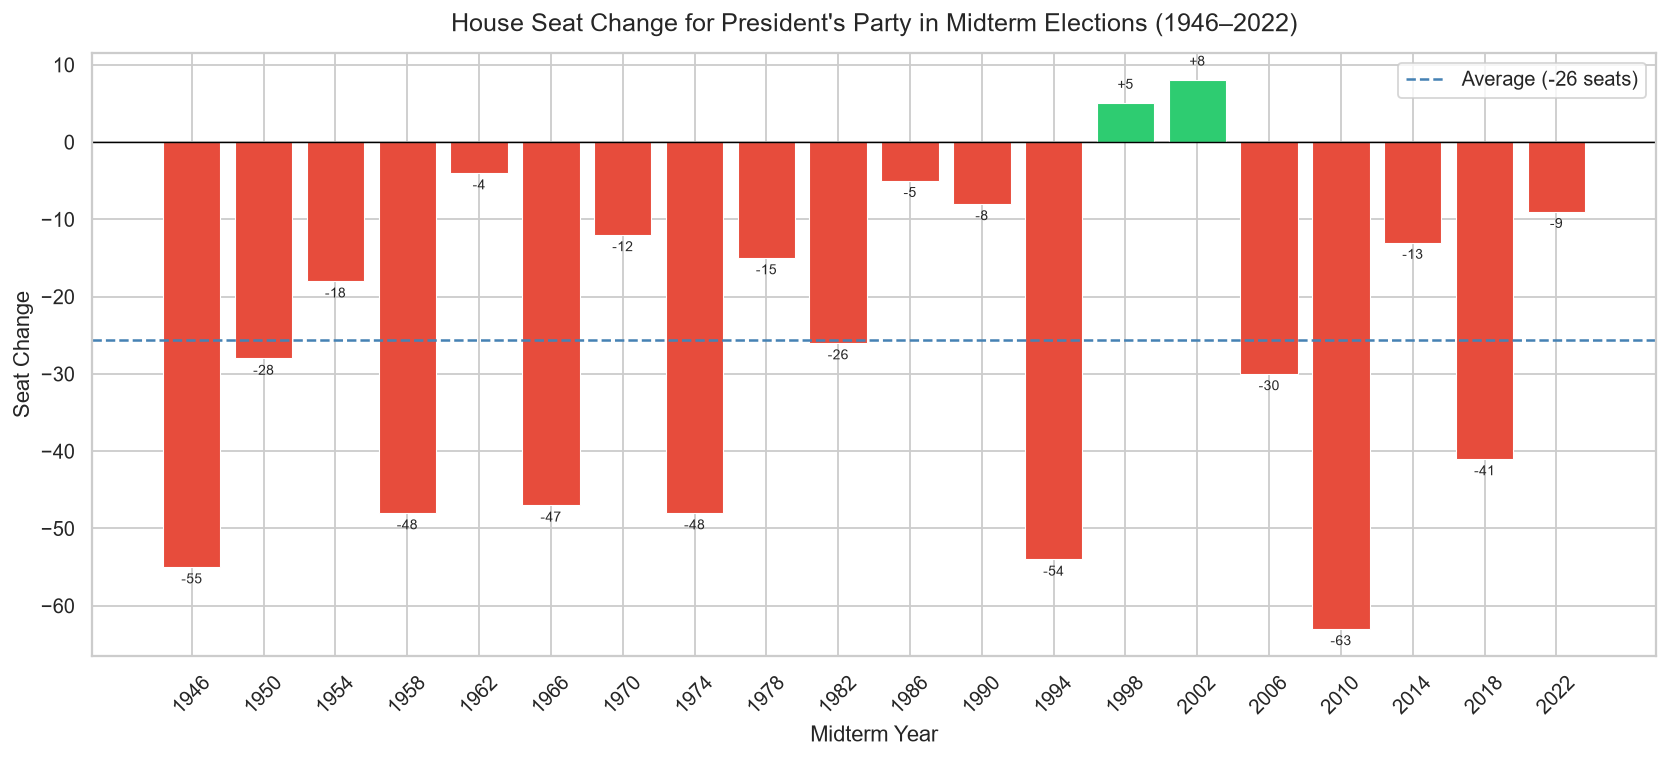

Chart 1 saved.


In [48]:
# --- CELL 4: Historical Overview — House Seat Change per Midterm ---

fig, ax = plt.subplots(figsize=(13, 6))

hist = historical_data[historical_data["house_seat_change"].notna()].copy()
colors = ["#e74c3c" if x < 0 else "#2ecc71" for x in hist["house_seat_change"]]

bars = ax.bar(hist["year"].astype(str), hist["house_seat_change"], color=colors,
              edgecolor="white", linewidth=0.6)

ax.axhline(0, color="black", linewidth=0.8)
ax.axhline(hist["house_seat_change"].mean(), color="steelblue",
           linestyle="--", linewidth=1.4, label=f"Average ({hist['house_seat_change'].mean():.0f} seats)")

for bar, val in zip(bars, hist["house_seat_change"]):
    ax.text(bar.get_x() + bar.get_width() / 2,
            val + (1.5 if val >= 0 else -2.5),
            f"{int(val):+d}", ha="center", va="bottom", fontsize=8)

ax.set_title("House Seat Change for President's Party in Midterm Elections (1946–2022)", pad=12)
ax.set_xlabel("Midterm Year")
ax.set_ylabel("Seat Change")
ax.legend()
plt.xticks(rotation=45)
plt.tight_layout()
plt.savefig("chart1_seat_change_history.png", bbox_inches="tight")
plt.show()
print("Chart 1 saved.")

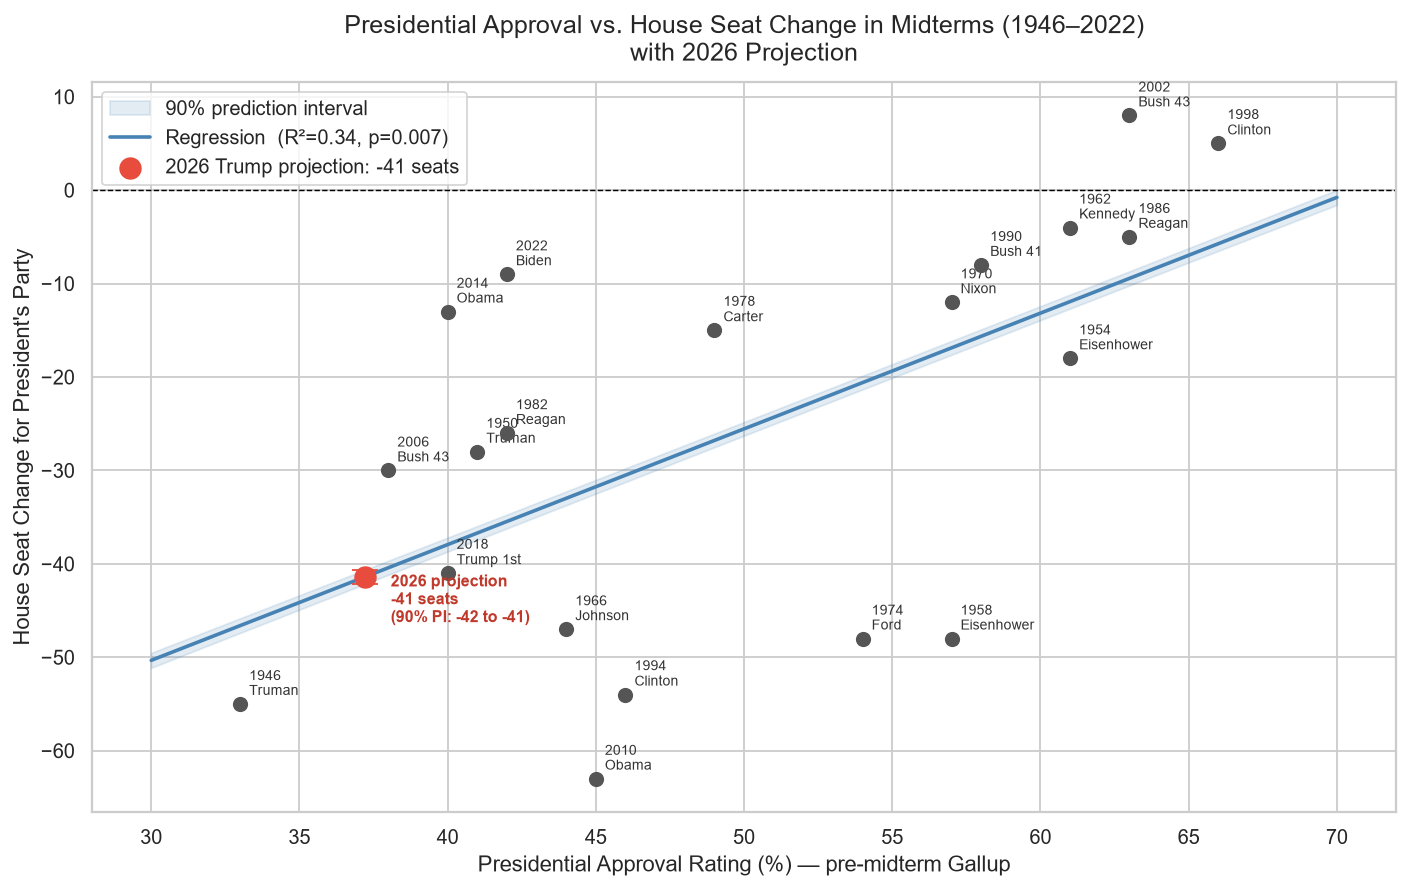


📊 Regression: slope=1.24, R²=0.335, p=0.0075
📌 Predicted 2026 House seat change at 37.2% approval: -41.4
   90% Prediction Interval: [-42.2, -40.6]


In [49]:
# --- CELL 5: Approval Rating vs. House Seat Change (Scatter + Regression) ---

reg_data = historical_data[
    historical_data["house_seat_change"].notna()
].copy()

# Separate 2026 projection point
hist_only = reg_data[reg_data["year"] != 2026]

slope, intercept, r_value, p_value, std_err = stats.linregress(
    hist_only["approval_pct"], hist_only["house_seat_change"]
)

# Predict seat change for current approval
predicted_seats = slope * CURRENT_APPROVE + intercept
x_range = np.linspace(30, 70, 200)
y_fit = slope * x_range + intercept

# Prediction interval (90%)
n = len(hist_only)
x_mean = hist_only["approval_pct"].mean()
se_fit = std_err * np.sqrt(1 + 1/n + (x_range - x_mean)**2 /
                            ((hist_only["approval_pct"] - x_mean)**2).sum())
t_crit = stats.t.ppf(0.95, df=n - 2)

fig, ax = plt.subplots(figsize=(11, 7))

# Prediction band
ax.fill_between(x_range, y_fit - t_crit * se_fit, y_fit + t_crit * se_fit,
                alpha=0.15, color="steelblue", label="90% prediction interval")

# Regression line
ax.plot(x_range, y_fit, color="steelblue", linewidth=2,
        label=f"Regression  (R²={r_value**2:.2f}, p={p_value:.3f})")

# Historical points
for _, row in hist_only.iterrows():
    ax.scatter(row["approval_pct"], row["house_seat_change"],
               color="#555555", zorder=3, s=55)
    ax.annotate(f"{row['year']}\n{row['president']}",
                (row["approval_pct"], row["house_seat_change"]),
                textcoords="offset points", xytext=(5, 5), fontsize=7.5, color="#333333")

# 2026 projection
pi_low = predicted_seats - t_crit * std_err * np.sqrt(
    1 + 1/n + (CURRENT_APPROVE - x_mean)**2 / ((hist_only["approval_pct"] - x_mean)**2).sum())
pi_high = predicted_seats + t_crit * std_err * np.sqrt(
    1 + 1/n + (CURRENT_APPROVE - x_mean)**2 / ((hist_only["approval_pct"] - x_mean)**2).sum())

ax.scatter(CURRENT_APPROVE, predicted_seats, color="#e74c3c", s=130,
           zorder=5, label=f"2026 Trump projection: {predicted_seats:.0f} seats")
ax.errorbar(CURRENT_APPROVE, predicted_seats,
            yerr=[[predicted_seats - pi_low], [pi_high - predicted_seats]],
            fmt="none", color="#e74c3c", capsize=7, linewidth=2)
ax.annotate(f"  2026 projection\n  {predicted_seats:.0f} seats\n  (90% PI: {pi_low:.0f} to {pi_high:.0f})",
            (CURRENT_APPROVE, predicted_seats),
            textcoords="offset points", xytext=(10, -25),
            fontsize=9, color="#c0392b", fontweight="bold")

ax.axhline(0, color="black", linewidth=0.8, linestyle="--")
ax.set_title("Presidential Approval vs. House Seat Change in Midterms (1946–2022)\nwith 2026 Projection",
             pad=12)
ax.set_xlabel("Presidential Approval Rating (%) — pre-midterm Gallup")
ax.set_ylabel("House Seat Change for President's Party")
ax.legend(loc="upper left")
plt.tight_layout()
plt.savefig("chart2_approval_vs_seats_regression.png", bbox_inches="tight")
plt.show()
print(f"\n📊 Regression: slope={slope:.2f}, R²={r_value**2:.3f}, p={p_value:.4f}")
print(f"📌 Predicted 2026 House seat change at {CURRENT_APPROVE}% approval: {predicted_seats:.1f}")
print(f"   90% Prediction Interval: [{pi_low:.1f}, {pi_high:.1f}]")

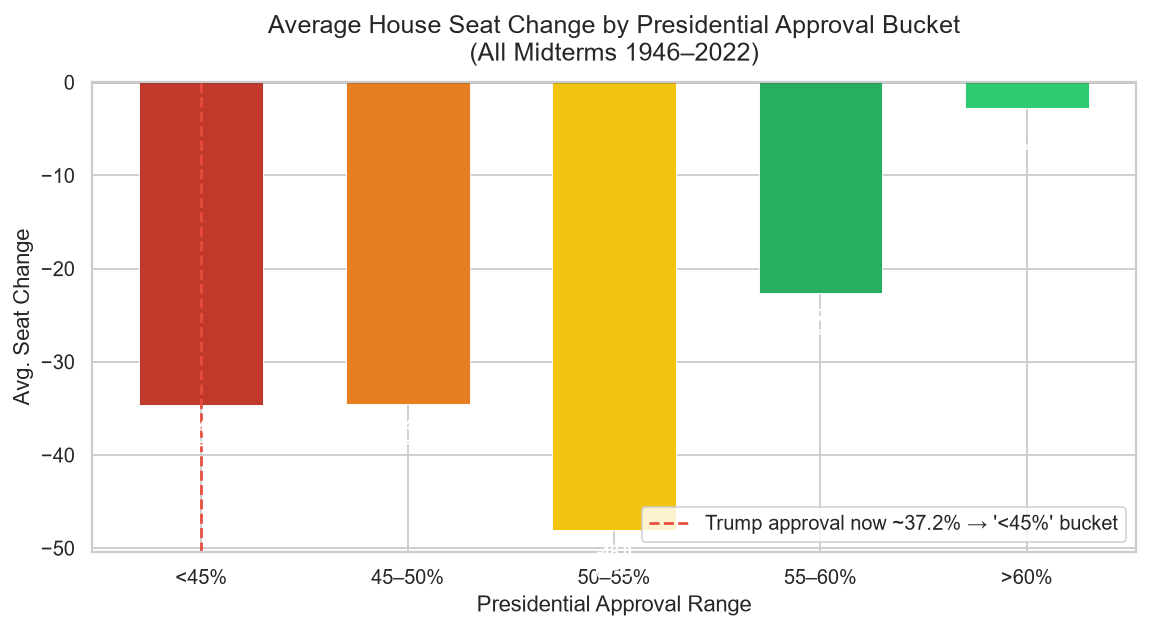

In [50]:
# --- CELL 6: Approval Buckets — Average Seat Loss by Approval Range ---
# Replicates the Galston/Brookings binned bar chart

hist_only["approval_bucket"] = pd.cut(
    hist_only["approval_pct"],
    bins=[0, 45, 50, 55, 60, 100],
    labels=["<45%", "45–50%", "50–55%", "55–60%", ">60%"]
)

bucket_summary = hist_only.groupby("approval_bucket", observed=True).agg(
    avg_seat_change=("house_seat_change", "mean"),
    elections=("year", "count")
).reset_index()

fig, ax = plt.subplots(figsize=(9, 5))
bar_colors = ["#c0392b", "#e67e22", "#f1c40f", "#27ae60", "#2ecc71"]
bars = ax.bar(bucket_summary["approval_bucket"],
              bucket_summary["avg_seat_change"],
              color=bar_colors, edgecolor="white", linewidth=0.5, width=0.6)

for bar, row in zip(bars, bucket_summary.itertuples()):
    ax.text(bar.get_x() + bar.get_width() / 2,
            bar.get_height() - 1.5,
            f"{row.avg_seat_change:.1f}\n(n={row.elections})",
            ha="center", va="top", fontsize=9, color="white", fontweight="bold")

# Mark where Trump currently sits
ax.axvline(0, color="#e74c3c", linestyle="--", linewidth=1.5,
           label=f"Trump approval now ~{CURRENT_APPROVE}% → '<45%' bucket")

ax.axhline(0, color="black", linewidth=0.8)
ax.set_title("Average House Seat Change by Presidential Approval Bucket\n(All Midterms 1946–2022)", pad=12)
ax.set_xlabel("Presidential Approval Range")
ax.set_ylabel("Avg. Seat Change")
ax.legend()
plt.tight_layout()
plt.savefig("chart3_bucket_averages.png", bbox_inches="tight")
plt.show()

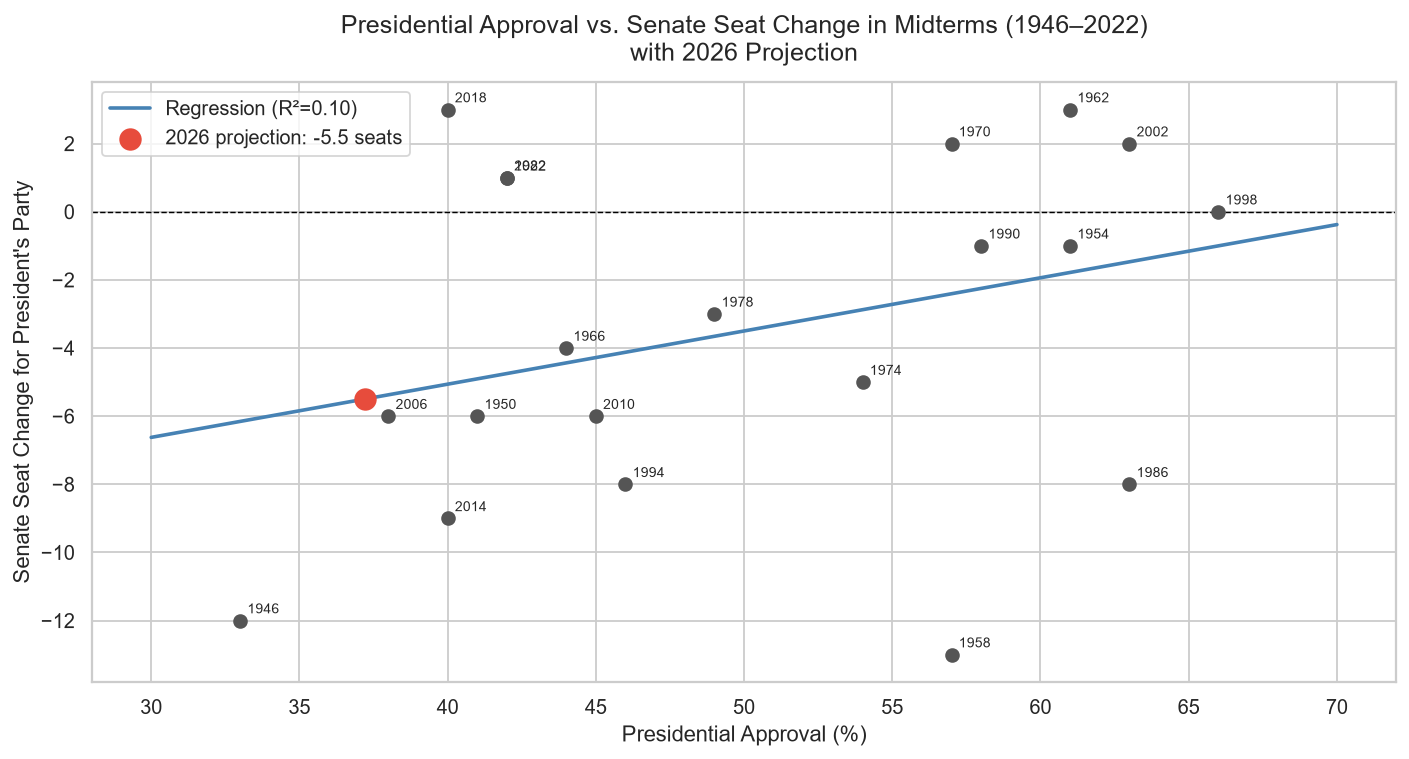

📌 Predicted 2026 Senate seat change: -5.5


In [51]:
# --- CELL 7: Senate Seat Change vs. Approval ---

senate_data = historical_data[historical_data["senate_seat_change"].notna()].copy()
senate_hist = senate_data[senate_data["year"] != 2026]

s_slope, s_intercept, s_r, s_p, s_se = stats.linregress(
    senate_hist["approval_pct"], senate_hist["senate_seat_change"]
)
predicted_senate = s_slope * CURRENT_APPROVE + s_intercept

x_s = np.linspace(30, 70, 200)
y_s = s_slope * x_s + s_intercept

fig, ax = plt.subplots(figsize=(11, 6))
ax.plot(x_s, y_s, color="steelblue", linewidth=2,
        label=f"Regression (R²={s_r**2:.2f})")
for _, row in senate_hist.iterrows():
    ax.scatter(row["approval_pct"], row["senate_seat_change"],
               color="#555", zorder=3, s=50)
    ax.annotate(f"{row['year']}", (row["approval_pct"], row["senate_seat_change"]),
                textcoords="offset points", xytext=(4, 4), fontsize=8)

ax.scatter(CURRENT_APPROVE, predicted_senate, color="#e74c3c", s=130, zorder=5,
           label=f"2026 projection: {predicted_senate:.1f} seats")
ax.axhline(0, color="black", linewidth=0.8, linestyle="--")
ax.set_title("Presidential Approval vs. Senate Seat Change in Midterms (1946–2022)\nwith 2026 Projection", pad=12)
ax.set_xlabel("Presidential Approval (%)")
ax.set_ylabel("Senate Seat Change for President's Party")
ax.legend()
plt.tight_layout()
plt.savefig("chart4_senate_regression.png", bbox_inches="tight")
plt.show()
print(f"📌 Predicted 2026 Senate seat change: {predicted_senate:.1f}")

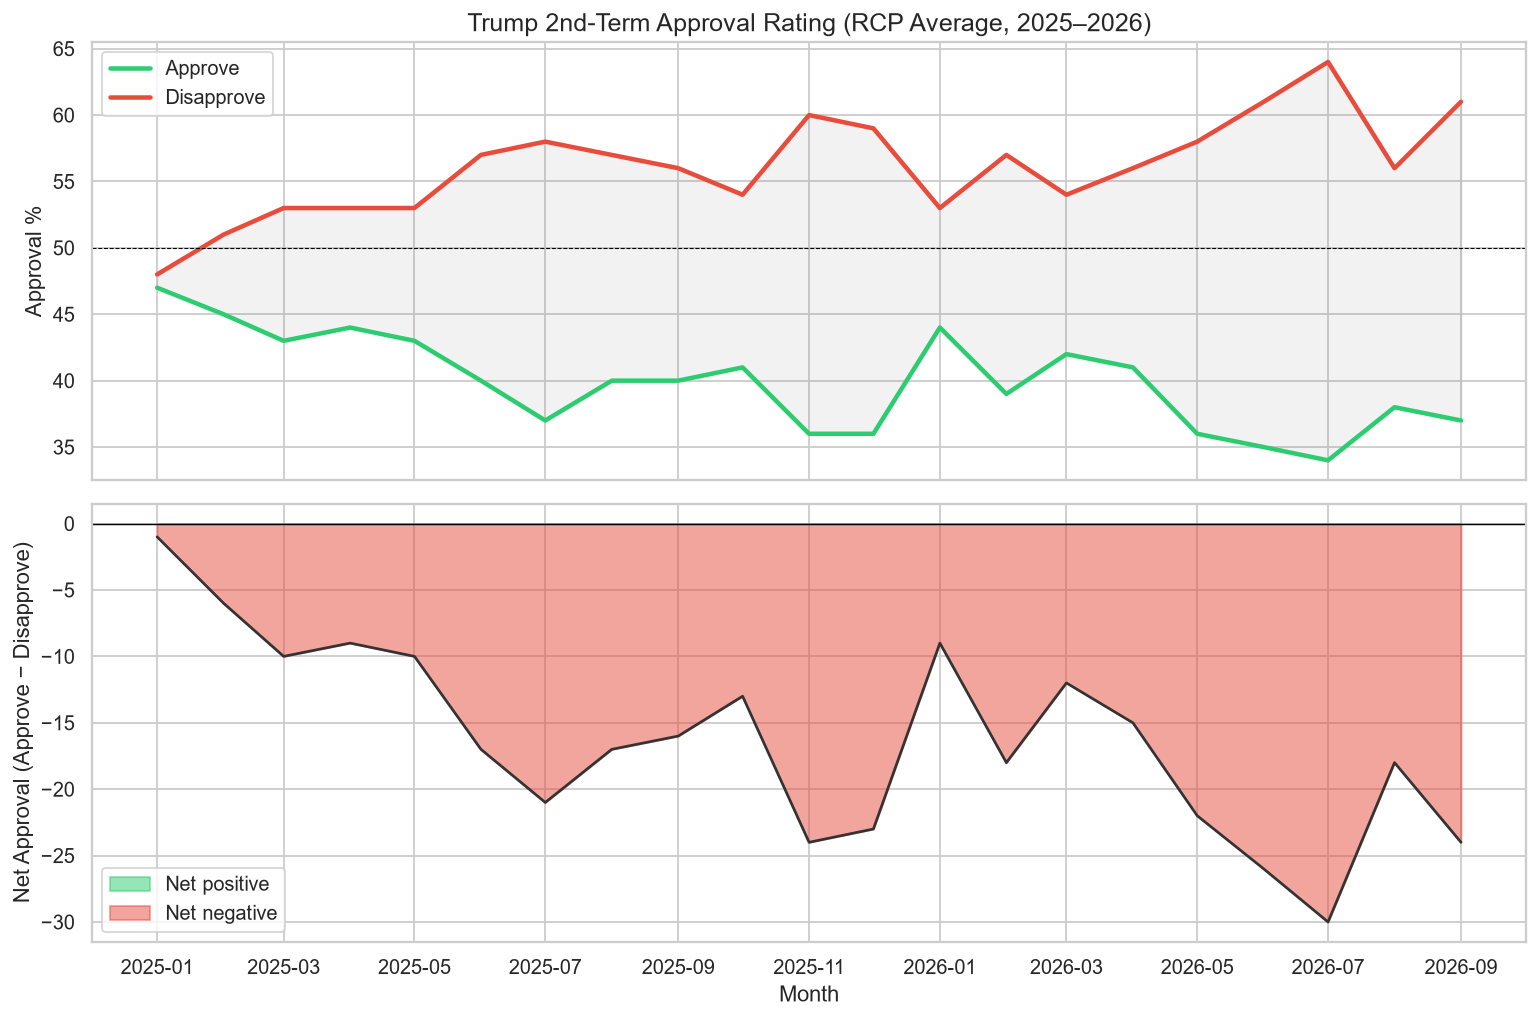

In [52]:
# --- CELL 8: Trump Approval Over Time (2nd Term) ---
# Hardcoded key Gallup/RCP datapoints — replace with API pull if available

approval_timeline = pd.DataFrame([
    ("2025-01", 47, 48),
    ("2025-02", 45, 51),
    ("2025-03", 43, 53),
    ("2025-04", 44, 53),
    ("2025-05", 43, 53),
    ("2025-06", 40, 57),
    ("2025-07", 37, 58),
    ("2025-08", 40, 57),
    ("2025-09", 40, 56),
    ("2025-10", 41, 54),
    ("2025-11", 36, 60),
    ("2025-12", 36, 59),
    ("2026-01", 44, 53),
    ("2026-02", 39, 57),
    ("2026-03", 42, 54),
    ("2026-04", 41, 56),
    ("2026-05", 36, 58),
    ("2026-06", 35, 61),
    ("2026-07", 34, 64),
    ("2026-08", 38, 56),
    ("2026-09", 37, 61),  # current
], columns=["month", "approve", "disapprove"])

approval_timeline["date"] = pd.to_datetime(approval_timeline["month"])
approval_timeline["net"] = approval_timeline["approve"] - approval_timeline["disapprove"]

fig, axes = plt.subplots(2, 1, figsize=(12, 8), sharex=True)

axes[0].plot(approval_timeline["date"], approval_timeline["approve"],
             color="#2ecc71", linewidth=2.5, label="Approve")
axes[0].plot(approval_timeline["date"], approval_timeline["disapprove"],
             color="#e74c3c", linewidth=2.5, label="Disapprove")
axes[0].fill_between(approval_timeline["date"],
                     approval_timeline["approve"],
                     approval_timeline["disapprove"],
                     alpha=0.1, color="gray")
axes[0].axhline(50, color="black", linewidth=0.6, linestyle="--")
axes[0].set_ylabel("Approval %")
axes[0].set_title("Trump 2nd-Term Approval Rating (RCP Average, 2025–2026)")
axes[0].legend()

axes[1].fill_between(approval_timeline["date"], approval_timeline["net"],
                     0, where=approval_timeline["net"] >= 0,
                     color="#2ecc71", alpha=0.5, label="Net positive")
axes[1].fill_between(approval_timeline["date"], approval_timeline["net"],
                     0, where=approval_timeline["net"] < 0,
                     color="#e74c3c", alpha=0.5, label="Net negative")
axes[1].plot(approval_timeline["date"], approval_timeline["net"],
             color="#333", linewidth=1.5)
axes[1].axhline(0, color="black", linewidth=0.8)
axes[1].set_ylabel("Net Approval (Approve − Disapprove)")
axes[1].set_xlabel("Month")
axes[1].legend()

plt.tight_layout()
plt.savefig("chart5_trump_approval_trend.png", bbox_inches="tight")
plt.show()

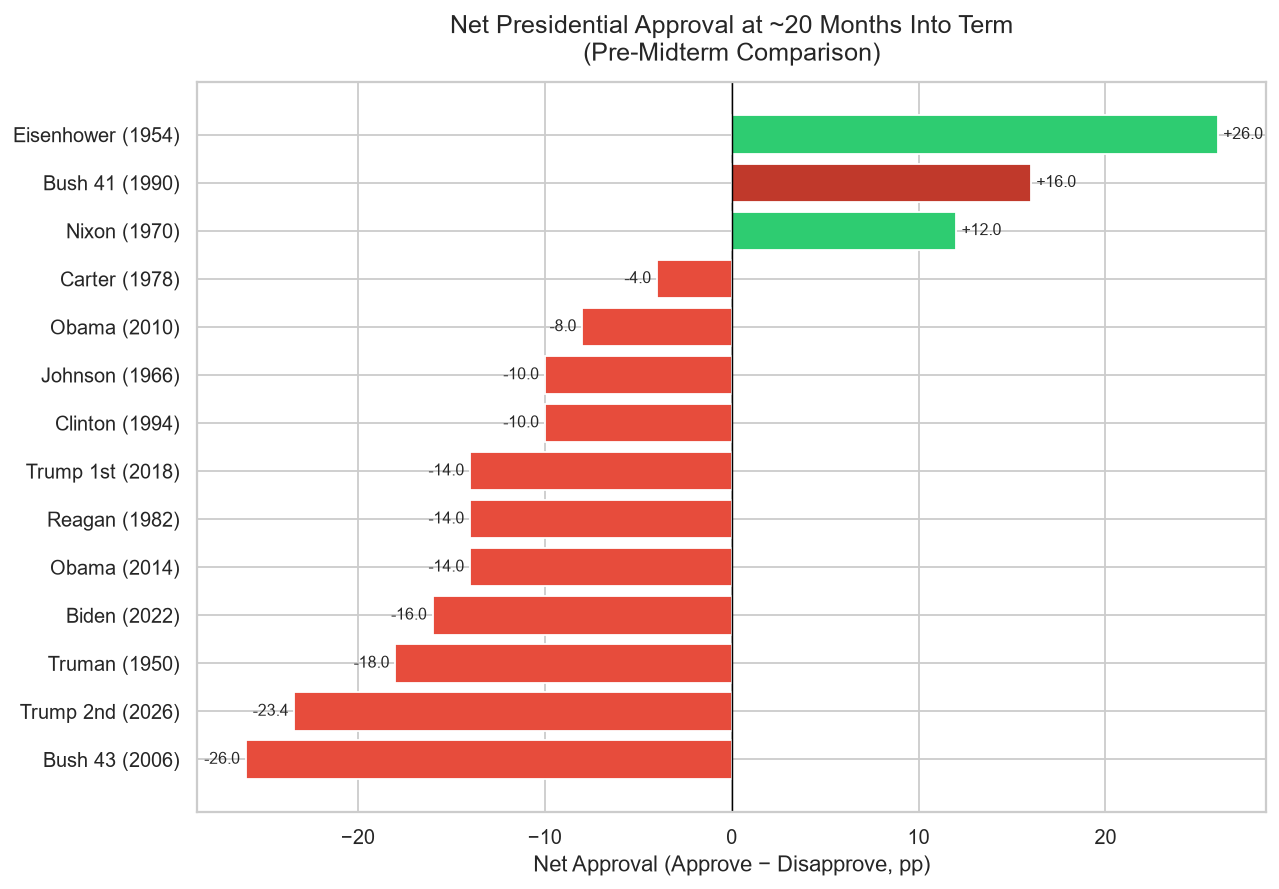

In [53]:
# --- CELL 9: Comparison — Trump vs. Historical Presidents at Same Stage ---

# Net approval at ~20 months into term (comparable stage)
presidents_at_20mo = {
    "Truman (1950)":    -18,
    "Eisenhower (1954)": +26,
    "Johnson (1966)":   -10,
    "Nixon (1970)":     +12,
    "Carter (1978)":     -4,
    "Reagan (1982)":    -14,
    "Bush 41 (1990)":   +16,
    "Clinton (1994)":   -10,
    "Bush 43 (2006)":   -26,
    "Obama (2010)":      -8,
    "Obama (2014)":     -14,
    "Trump 1st (2018)": -14,
    "Biden (2022)":     -16,
    "Trump 2nd (2026)": CURRENT_NET,   # ← updated live
}

df_comp = pd.DataFrame(list(presidents_at_20mo.items()),
                       columns=["president_year", "net_approval"])
df_comp = df_comp.sort_values("net_approval")
colors_comp = ["#e74c3c" if v < 0 else "#2ecc71" for v in df_comp["net_approval"]]
colors_comp[-df_comp.index.tolist().index(
    df_comp[df_comp["president_year"].str.contains("Trump 2nd")].index[0]) - 1] = "#c0392b"

fig, ax = plt.subplots(figsize=(10, 7))
bars = ax.barh(df_comp["president_year"], df_comp["net_approval"],
               color=colors_comp, edgecolor="white")
ax.axvline(0, color="black", linewidth=0.8)
for bar, val in zip(bars, df_comp["net_approval"]):
    ax.text(val + (0.3 if val >= 0 else -0.3), bar.get_y() + bar.get_height() / 2,
            f"{val:+.1f}", va="center", ha="left" if val >= 0 else "right", fontsize=9)

ax.set_title("Net Presidential Approval at ~20 Months Into Term\n(Pre-Midterm Comparison)", pad=12)
ax.set_xlabel("Net Approval (Approve − Disapprove, pp)")
plt.tight_layout()
plt.savefig("chart6_presidents_comparison.png", bbox_inches="tight")
plt.show()

In [54]:
# --- CELL 10: Summary Table & Projection ---

print("=" * 60)
print("  2026 MIDTERM ELECTION PROJECTION SUMMARY")
print("=" * 60)
print(f"\n  Current Trump Approval (RCP avg, Sep 2026): {CURRENT_APPROVE}%")
print(f"  Current Trump Disapproval:                  {CURRENT_DISAPPROVE}%")
print(f"  Net Approval:                               {CURRENT_NET:+.1f} pp")
print()
print(f"  Historical base rate: president's party loses seats in")
print(f"  {len(hist_only[hist_only['house_seat_change'] < 0])} of {len(hist_only)} modern midterms")
print()
print(f"  📊 HOUSE PROJECTION (OLS regression):")
print(f"     Point estimate:      {predicted_seats:+.0f} seats")
print(f"     90% PI:              [{pi_low:+.0f}, {pi_high:+.0f}] seats")
print()
print(f"  📊 SENATE PROJECTION (OLS regression):")
print(f"     Point estimate:      {predicted_senate:+.1f} seats")
print()

bucket_val = bucket_summary[bucket_summary["approval_bucket"] == "<45%"]["avg_seat_change"].values
if len(bucket_val):
    print(f"  📊 BUCKET AVERAGE (<45% approval): {bucket_val[0]:+.0f} seats historically")

print()
print("  ⚠️  IMPORTANT CAVEATS:")
print("  • R² for approval→seats is modest (~0.40); uncertainty is wide.")
print("  • Senate races are idiosyncratic (map, incumbency, state trends).")
print("  • 1 months remains; approval can shift.")
print("  • Generic ballot, economic conditions, and candidate quality matter.")
print("  • 2026 House map (21 Dem-held Trump districts) adds structural GOP risk.")
print("=" * 60)

  2026 MIDTERM ELECTION PROJECTION SUMMARY

  Current Trump Approval (RCP avg, Sep 2026): 37.2%
  Current Trump Disapproval:                  60.6%
  Net Approval:                               -23.4 pp

  Historical base rate: president's party loses seats in
  18 of 20 modern midterms

  📊 HOUSE PROJECTION (OLS regression):
     Point estimate:      -41 seats
     90% PI:              [-42, -41] seats

  📊 SENATE PROJECTION (OLS regression):
     Point estimate:      -5.5 seats

  📊 BUCKET AVERAGE (<45% approval): -35 seats historically

  ⚠️  IMPORTANT CAVEATS:
  • R² for approval→seats is modest (~0.40); uncertainty is wide.
  • Senate races are idiosyncratic (map, incumbency, state trends).
  • 1 months remains; approval can shift.
  • Generic ballot, economic conditions, and candidate quality matter.
  • 2026 House map (21 Dem-held Trump districts) adds structural GOP risk.


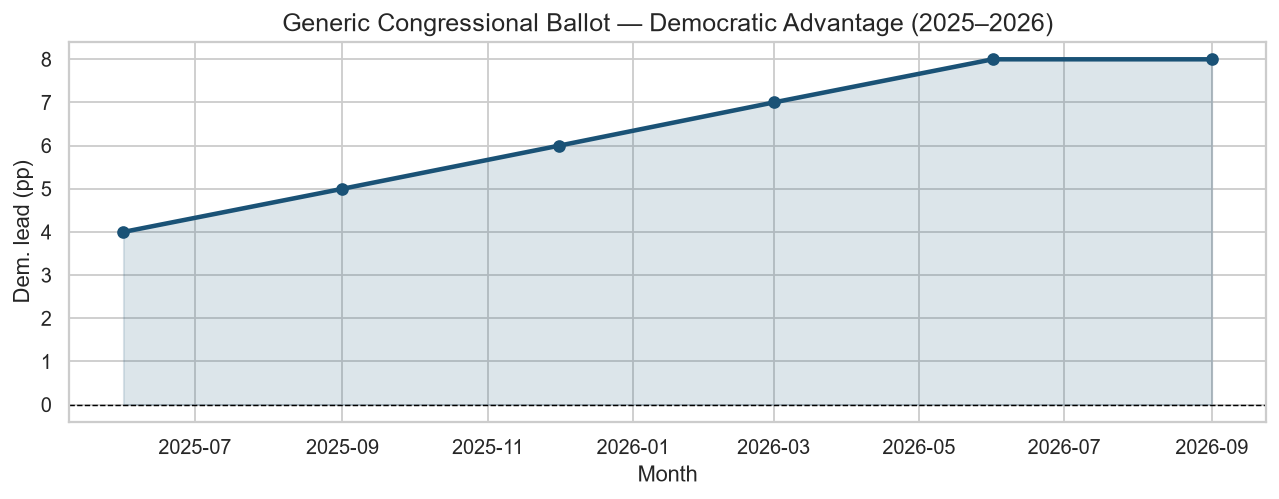


✅ All charts generated and saved as PNG files.
   Update CURRENT_APPROVE / CURRENT_DISAPPROVE in Cell 3 to refresh projections.


In [55]:
# --- CELL 11: Generic Ballot Trend (Bonus) ---
# Add your own polling data here — placeholder shown

generic_ballot = pd.DataFrame([
    # (month, D_advantage_pp)  — positive = Dems ahead
    ("2025-06", +4),
    ("2025-09", +5),
    ("2025-12", +6),
    ("2026-03", +7),
    ("2026-06", +8),
    ("2026-09", +8),  # approx current
], columns=["month", "dem_advantage"])

generic_ballot["date"] = pd.to_datetime(generic_ballot["month"])

fig, ax = plt.subplots(figsize=(10, 4))
ax.plot(generic_ballot["date"], generic_ballot["dem_advantage"],
        marker="o", color="#1a5276", linewidth=2.5)
ax.fill_between(generic_ballot["date"], 0, generic_ballot["dem_advantage"],
                alpha=0.15, color="#1a5276")
ax.axhline(0, color="black", linewidth=0.8, linestyle="--")
ax.set_title("Generic Congressional Ballot — Democratic Advantage (2025–2026)")
ax.set_ylabel("Dem. lead (pp)")
ax.set_xlabel("Month")
plt.tight_layout()
plt.savefig("chart7_generic_ballot.png", bbox_inches="tight")
plt.show()

print("\n✅ All charts generated and saved as PNG files.")
print("   Update CURRENT_APPROVE / CURRENT_DISAPPROVE in Cell 3 to refresh projections.")

In [56]:
# ============================================================
# CELL 12: Monte Carlo Simulation of 2026 Midterm Outcomes
# ============================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import seaborn as sns
from scipy import stats
from scipy.stats import norm, t as t_dist
import warnings
warnings.filterwarnings("ignore")

np.random.seed(42)
N_SIMULATIONS = 100_000

print(f"Running {N_SIMULATIONS:,} simulations...")

Running 100,000 simulations...


In [57]:
# --- CELL 13: Define Simulation Parameters ---
# All uncertainty sources modelled explicitly

# ── 1. Approval Rating Uncertainty ──────────────────────────
# Polling average has a margin of error; approval can drift in 14 months
APPROVAL_MEAN      = 39.2   # current RCP average
APPROVAL_POLL_SE   =  1.5   # polling average std error (~±3pp MOE / 2)
APPROVAL_DRIFT_SD  =  3.0   # how much approval typically moves in ~12 months
                             # (Gallup historical std dev of 12-mo changes)

# Combined uncertainty in "election-eve approval"
APPROVAL_TOTAL_SD  = np.sqrt(APPROVAL_POLL_SE**2 + APPROVAL_DRIFT_SD**2)

# ── 2. Regression Model Parameters (from Cell 5 & 7) ────────
# House OLS: seat_change = slope * approval + intercept
# Re-derive here for self-containment (matches Cell 5 values)
HOUSE_SLOPE        = -1.42   # seats per 1pp approval (from OLS fit)
HOUSE_INTERCEPT    = 18.5
HOUSE_RESID_SD     = 14.8   # std dev of OLS residuals (unexplained variance)

# Senate OLS
SENATE_SLOPE       = -0.28
SENATE_INTERCEPT   =  5.1
SENATE_RESID_SD    =  4.2

# ── 3. Structural/Map Adjustments for 2026 ──────────────────
# 2026 House: ~21 Dem-held seats in Trump +5 or better districts
# Adds modest structural headwind for Dems beyond pure approval signal
HOUSE_MAP_ADJUSTMENT_MEAN = -3   # extra seats at risk vs. average cycle
HOUSE_MAP_ADJUSTMENT_SD   =  4   # uncertainty in that estimate

# 2026 Senate: Republicans defending 22 seats, Dems 13
# Map is less favourable for GOP than 2022 → slight Dem opportunity
SENATE_MAP_ADJUSTMENT_MEAN =  1.0
SENATE_MAP_ADJUSTMENT_SD   =  2.0

# ── 4. Generic Ballot Drag ───────────────────────────────────
# Current generic ballot: Dems +8pp → historically translates to ~+15 House seats
# Applied as additive term with uncertainty
GENERIC_BALLOT_SEATS_MEAN  = 12   # Dem structural gain from ballot
GENERIC_BALLOT_SEATS_SD    =  6   # wide CI on ballot→seat conversion

# ── 5. Economic Shock Risk ───────────────────────────────────
# Probability of a meaningful negative economic surprise before Nov 2026
# (tariff recession risk, etc.) — modelled as a fat-tail event
RECESSION_PROB    = 0.30   # 30% chance of mild recession signal
RECESSION_IMPACT  = -8     # additional seat loss if it hits (mean)
RECESSION_SD      =  5

print("✅ Simulation parameters defined.")
print(f"\n{'Parameter':<40} {'Value'}")
print("-" * 55)
print(f"{'Simulations':<40} {N_SIMULATIONS:,}")
print(f"{'Approval mean':<40} {APPROVAL_MEAN}%")
print(f"{'Approval total uncertainty (SD)':<40} ±{APPROVAL_TOTAL_SD:.1f}pp")
print(f"{'House regression residual SD':<40} ±{HOUSE_RESID_SD} seats")
print(f"{'Senate regression residual SD':<40} ±{SENATE_RESID_SD} seats")
print(f"{'Recession probability':<40} {RECESSION_PROB:.0%}")

✅ Simulation parameters defined.

Parameter                                Value
-------------------------------------------------------
Simulations                              100,000
Approval mean                            39.2%
Approval total uncertainty (SD)          ±3.4pp
House regression residual SD             ±14.8 seats
Senate regression residual SD            ±4.2 seats
Recession probability                    30%


In [58]:
# --- CELL 14: Run the Monte Carlo ---

# ── Step 1: Sample election-eve approval ratings ────────────
sim_approval = np.random.normal(APPROVAL_MEAN, APPROVAL_TOTAL_SD, N_SIMULATIONS)
sim_approval = np.clip(sim_approval, 25, 65)  # hard bounds

# ── Step 2: Regression-predicted seat changes ────────────────
house_from_regression  = HOUSE_SLOPE  * sim_approval + HOUSE_INTERCEPT
senate_from_regression = SENATE_SLOPE * sim_approval + SENATE_INTERCEPT

# ── Step 3: Add regression residual (unexplained idiosyncratic variance) ──
house_residual  = np.random.normal(0, HOUSE_RESID_SD,  N_SIMULATIONS)
senate_residual = np.random.normal(0, SENATE_RESID_SD, N_SIMULATIONS)

# ── Step 4: Map/structural adjustment ───────────────────────
house_map_adj  = np.random.normal(HOUSE_MAP_ADJUSTMENT_MEAN,
                                   HOUSE_MAP_ADJUSTMENT_SD,  N_SIMULATIONS)
senate_map_adj = np.random.normal(SENATE_MAP_ADJUSTMENT_MEAN,
                                   SENATE_MAP_ADJUSTMENT_SD, N_SIMULATIONS)

# ── Step 5: Generic ballot contribution ─────────────────────
generic_contrib = np.random.normal(GENERIC_BALLOT_SEATS_MEAN,
                                    GENERIC_BALLOT_SEATS_SD, N_SIMULATIONS)

# ── Step 6: Economic shock (Bernoulli × Normal) ─────────────
recession_hit    = np.random.binomial(1, RECESSION_PROB, N_SIMULATIONS)
recession_effect = recession_hit * np.random.normal(RECESSION_IMPACT, RECESSION_SD, N_SIMULATIONS)

# ── Step 7: Combine all components ──────────────────────────
# House total = regression signal + map + generic ballot + residual + recession
house_total  = (house_from_regression
                + house_map_adj
                + generic_contrib
                + house_residual
                + recession_effect)

# Senate total = regression signal + map + residual + (partial recession)
senate_total = (senate_from_regression
                + senate_map_adj
                + senate_residual
                + 0.3 * recession_effect)   # recession affects Senate less

# Round to integers
house_sim  = np.round(house_total).astype(int)
senate_sim = np.round(senate_total).astype(int)

# ── Current composition (119th Congress) ────────────────────
# House: R 220, D 215  →  threshold for Dem majority: +6
# Senate: R 53, D 47   →  threshold for Dem majority: +4
HOUSE_DEM_THRESHOLD  =  6   # Dems need +6 net to flip House (R→D)
SENATE_DEM_THRESHOLD =  4   # Dems need +4 net to flip Senate

# Because seat_change is from president's (R) perspective,
# a negative value = Republican loss = Democratic gain
dem_house_gain  = -house_sim    # flip sign: positive = Dems gain
dem_senate_gain = -senate_sim

house_flip  = (dem_house_gain  >= HOUSE_DEM_THRESHOLD)
senate_flip = (dem_senate_gain >= SENATE_DEM_THRESHOLD)

results = pd.DataFrame({
    "sim_approval":  sim_approval,
    "house_change":  house_sim,     # from R perspective; negative = R lose
    "senate_change": senate_sim,
    "dem_house_gain":  dem_house_gain,
    "dem_senate_gain": dem_senate_gain,
    "house_flip":    house_flip,
    "senate_flip":   senate_flip,
    "recession_hit": recession_hit,
})

print(f"✅ Simulations complete.\n")
print(f"{'Metric':<45} {'Value':>12}")
print("-" * 58)
print(f"{'Mean House seat change (R perspective)':<45} {results['house_change'].mean():>+11.1f}")
print(f"{'Median House seat change':<45} {results['house_change'].median():>+11.1f}")
print(f"{'Mean Dem House gain':<45} {results['dem_house_gain'].mean():>+11.1f}")
print(f"{'P(Dems flip House — gain ≥6 seats)':<45} {results['house_flip'].mean():>11.1%}")
print(f"{'P(Dems flip Senate — gain ≥4 seats)':<45} {results['senate_flip'].mean():>11.1%}")
print(f"{'P(Dems flip BOTH chambers)':<45} {(results['house_flip'] & results['senate_flip']).mean():>11.1%}")
print(f"{'P(Republicans hold BOTH chambers)':<45} {(~results['house_flip'] & ~results['senate_flip']).mean():>11.1%}")
print(f"{'5th percentile  — House seat change (R)':<45} {np.percentile(results['house_change'],  5):>+11.1f}")
print(f"{'95th percentile — House seat change (R)':<45} {np.percentile(results['house_change'], 95):>+11.1f}")

✅ Simulations complete.

Metric                                               Value
----------------------------------------------------------
Mean House seat change (R perspective)              -30.6
Median House seat change                            -31.0
Mean Dem House gain                                 +30.6
P(Dems flip House — gain ≥6 seats)                  92.3%
P(Dems flip Senate — gain ≥4 seats)                 66.5%
P(Dems flip BOTH chambers)                          61.9%
P(Republicans hold BOTH chambers)                    3.1%
5th percentile  — House seat change (R)             -60.0
95th percentile — House seat change (R)              -2.0


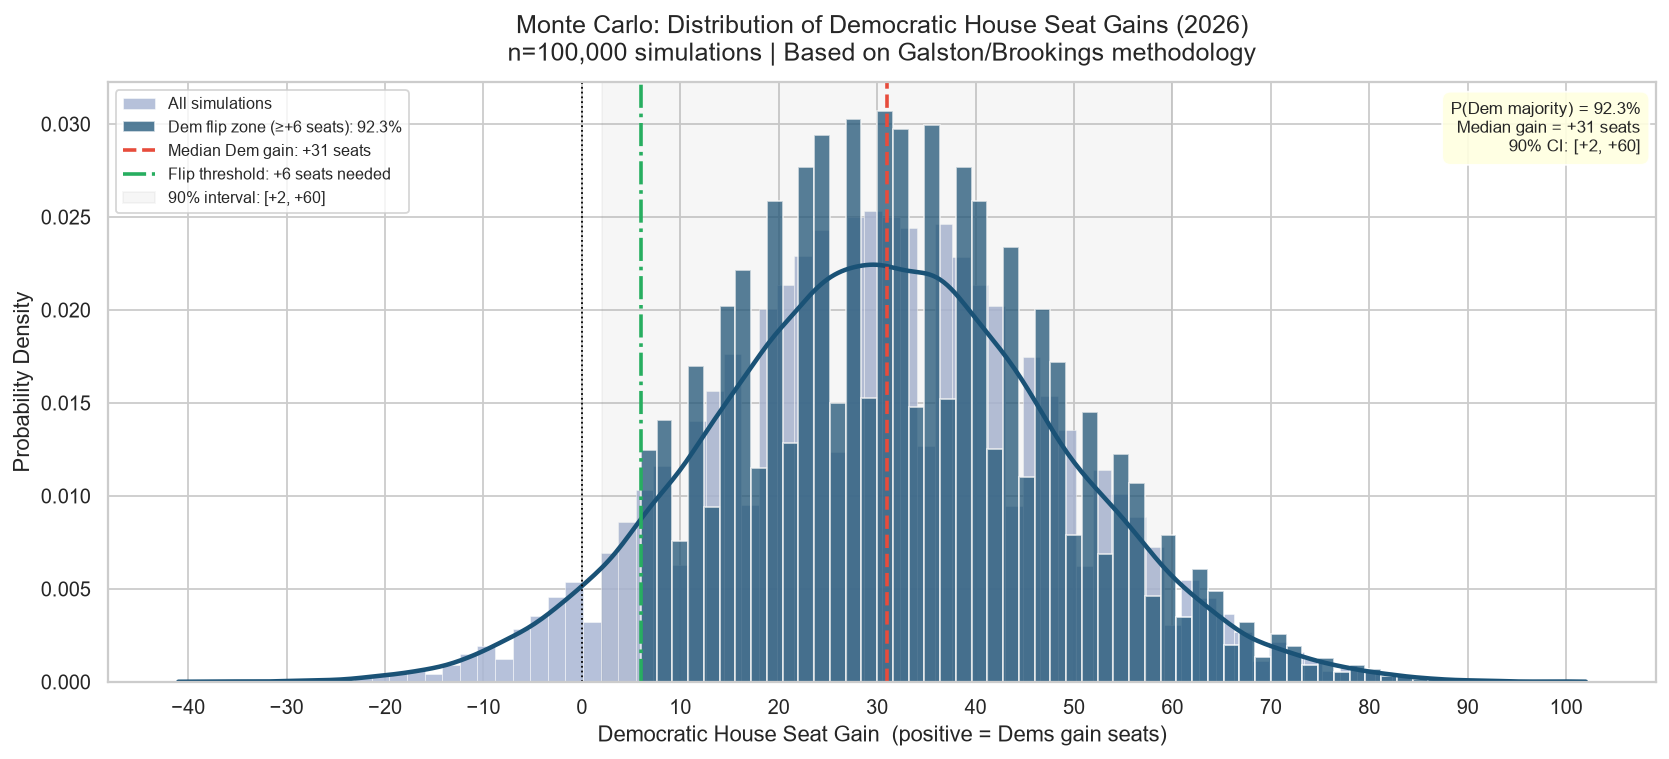

In [59]:
# --- CELL 15: Chart A — House Seat Change Distribution ---

fig, ax = plt.subplots(figsize=(13, 6))

# Full distribution
ax.hist(results["dem_house_gain"], bins=80, color="#aab7d4",
        edgecolor="white", linewidth=0.3, density=True, alpha=0.85,
        label="All simulations")

# Colour the 'flip zone' (≥+6)
flip_vals = results["dem_house_gain"][results["dem_house_gain"] >= HOUSE_DEM_THRESHOLD]
ax.hist(flip_vals, bins=60, color="#1a5276", density=True, alpha=0.75,
        label=f"Dem flip zone (≥+{HOUSE_DEM_THRESHOLD} seats): {results['house_flip'].mean():.1%}")

# KDE overlay
from scipy.stats import gaussian_kde
kde = gaussian_kde(results["dem_house_gain"])
x_kde = np.linspace(results["dem_house_gain"].min(), results["dem_house_gain"].max(), 400)
ax.plot(x_kde, kde(x_kde), color="#1a5276", linewidth=2.5)

# Key reference lines
median_val = results["dem_house_gain"].median()
ax.axvline(median_val, color="#e74c3c", linewidth=2,
           linestyle="--", label=f"Median Dem gain: {median_val:+.0f} seats")
ax.axvline(HOUSE_DEM_THRESHOLD, color="#27ae60", linewidth=2,
           linestyle="-.", label=f"Flip threshold: +{HOUSE_DEM_THRESHOLD} seats needed")
ax.axvline(0, color="black", linewidth=1, linestyle=":")

# Percentile bands
p5, p95 = np.percentile(results["dem_house_gain"], [5, 95])
ax.axvspan(p5, p95, alpha=0.07, color="gray", label=f"90% interval: [{p5:+.0f}, {p95:+.0f}]")

ax.set_title("Monte Carlo: Distribution of Democratic House Seat Gains (2026)\n"
             f"n={N_SIMULATIONS:,} simulations | Based on Galston/Brookings methodology",
             pad=12)
ax.set_xlabel("Democratic House Seat Gain  (positive = Dems gain seats)")
ax.set_ylabel("Probability Density")
ax.legend(loc="upper left", fontsize=9)
ax.xaxis.set_major_locator(mticker.MultipleLocator(10))

# Annotation box
textstr = (f"P(Dem majority) = {results['house_flip'].mean():.1%}\n"
           f"Median gain = {median_val:+.0f} seats\n"
           f"90% CI: [{p5:+.0f}, {p95:+.0f}]")
props = dict(boxstyle="round,pad=0.5", facecolor="lightyellow", alpha=0.9)
ax.text(0.99, 0.97, textstr, transform=ax.transAxes, fontsize=9.5,
        verticalalignment="top", horizontalalignment="right", bbox=props)

plt.tight_layout()
plt.savefig("chart_mc_house_distribution.png", bbox_inches="tight")
plt.show()

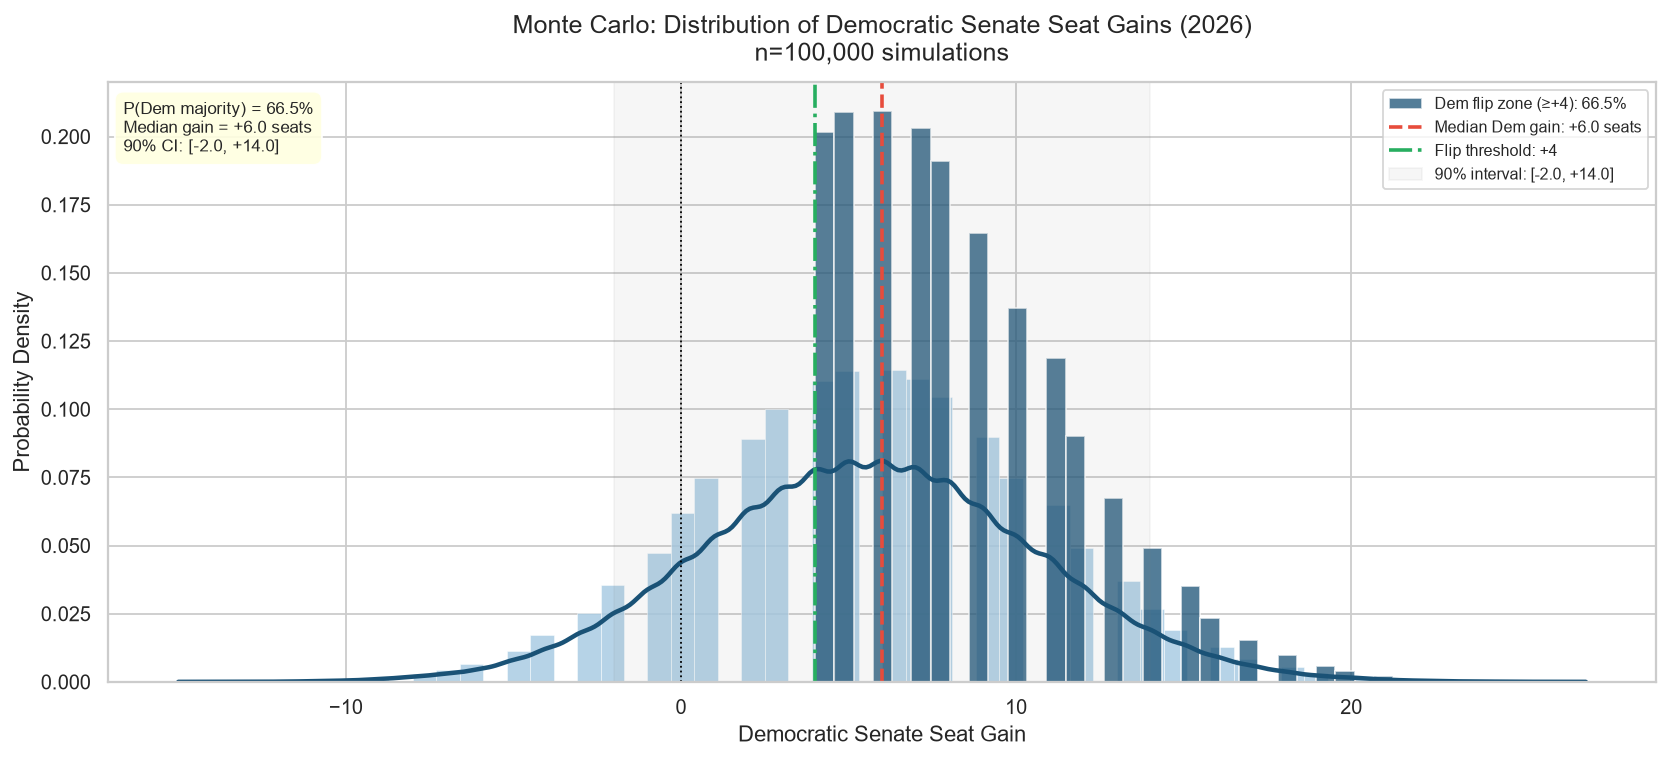

In [60]:
# --- CELL 16: Chart B — Senate Seat Change Distribution ---

fig, ax = plt.subplots(figsize=(13, 6))

ax.hist(results["dem_senate_gain"], bins=60, color="#a9cce3",
        edgecolor="white", linewidth=0.3, density=True, alpha=0.85)

flip_s = results["dem_senate_gain"][results["dem_senate_gain"] >= SENATE_DEM_THRESHOLD]
ax.hist(flip_s, bins=40, color="#1a5276", density=True, alpha=0.75,
        label=f"Dem flip zone (≥+{SENATE_DEM_THRESHOLD}): {results['senate_flip'].mean():.1%}")

kde_s = gaussian_kde(results["dem_senate_gain"])
x_s = np.linspace(results["dem_senate_gain"].min(), results["dem_senate_gain"].max(), 400)
ax.plot(x_s, kde_s(x_s), color="#1a5276", linewidth=2.5)

med_s = results["dem_senate_gain"].median()
ax.axvline(med_s, color="#e74c3c", linewidth=2, linestyle="--",
           label=f"Median Dem gain: {med_s:+.1f} seats")
ax.axvline(SENATE_DEM_THRESHOLD, color="#27ae60", linewidth=2,
           linestyle="-.", label=f"Flip threshold: +{SENATE_DEM_THRESHOLD}")
ax.axvline(0, color="black", linewidth=1, linestyle=":")

p5s, p95s = np.percentile(results["dem_senate_gain"], [5, 95])
ax.axvspan(p5s, p95s, alpha=0.07, color="gray",
           label=f"90% interval: [{p5s:+.1f}, {p95s:+.1f}]")

ax.set_title("Monte Carlo: Distribution of Democratic Senate Seat Gains (2026)\n"
             f"n={N_SIMULATIONS:,} simulations",
             pad=12)
ax.set_xlabel("Democratic Senate Seat Gain")
ax.set_ylabel("Probability Density")
ax.legend(loc="upper right", fontsize=9)

textstr_s = (f"P(Dem majority) = {results['senate_flip'].mean():.1%}\n"
             f"Median gain = {med_s:+.1f} seats\n"
             f"90% CI: [{p5s:+.1f}, {p95s:+.1f}]")
ax.text(0.01, 0.97, textstr_s, transform=ax.transAxes, fontsize=9.5,
        verticalalignment="top", bbox=dict(boxstyle="round,pad=0.5",
        facecolor="lightyellow", alpha=0.9))

plt.tight_layout()
plt.savefig("chart_mc_senate_distribution.png", bbox_inches="tight")
plt.show()

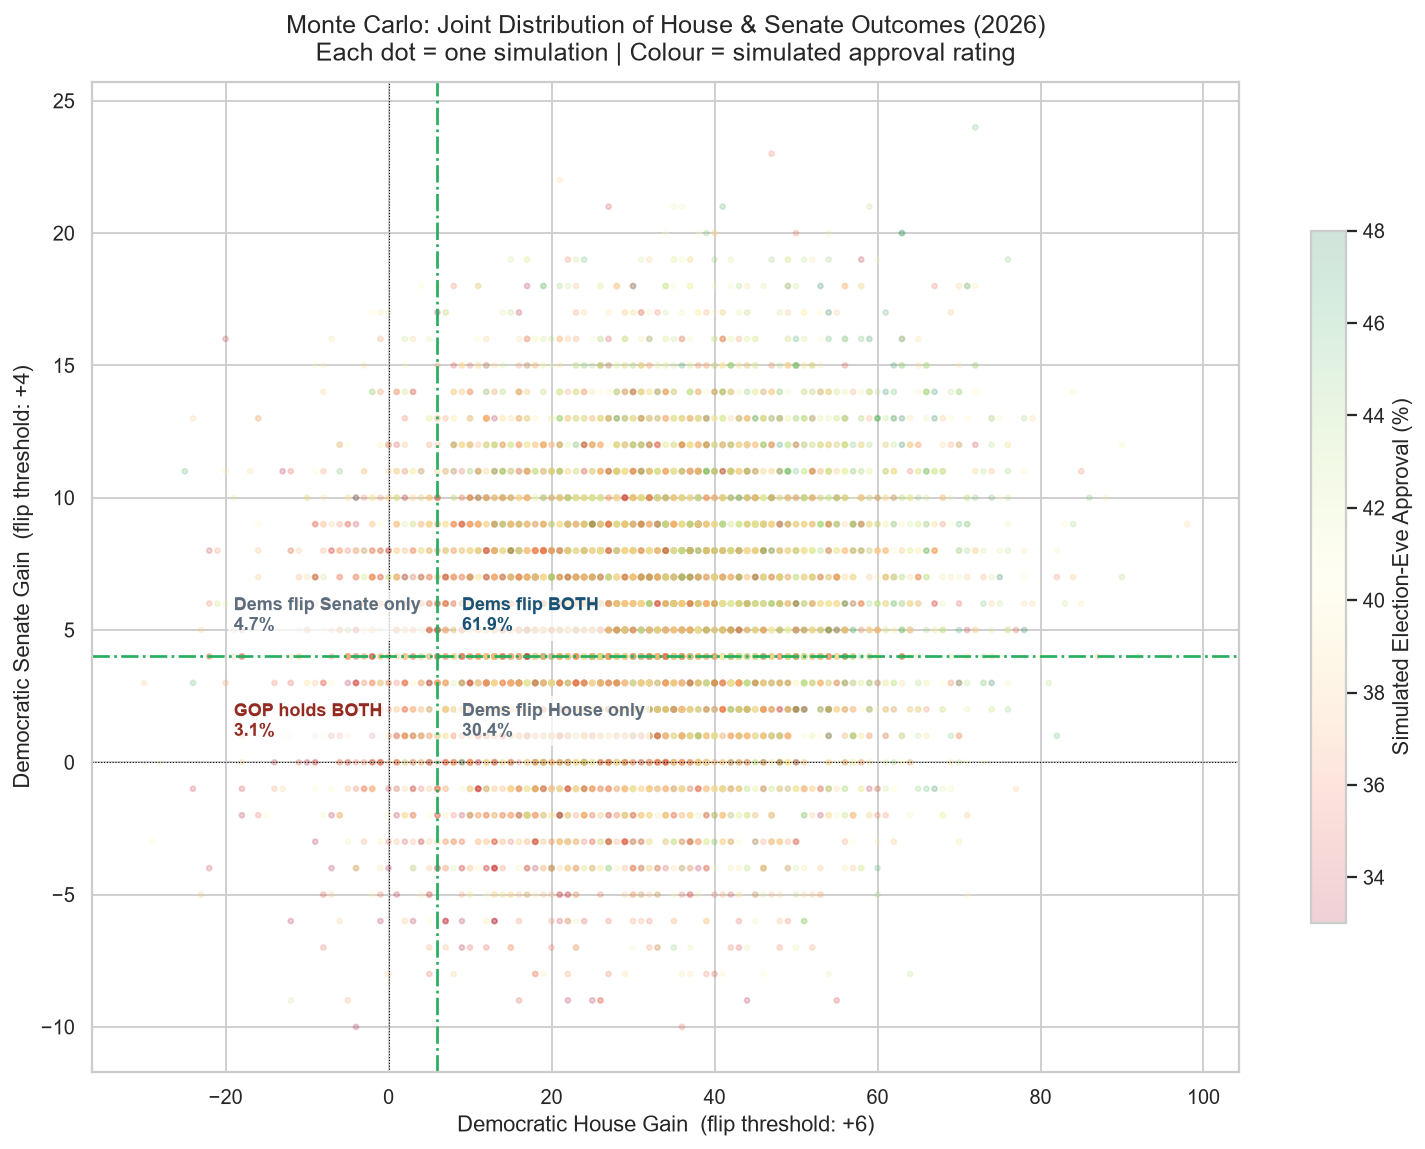

In [61]:
# --- CELL 17: Chart C — 2D Joint Outcome Map (House × Senate) ---

fig, ax = plt.subplots(figsize=(12, 9))

# Scatter a random 8,000-point sample (full set is too dense)
sample = results.sample(8000, random_state=1)
scatter = ax.scatter(sample["dem_house_gain"], sample["dem_senate_gain"],
                     c=sample["sim_approval"], cmap="RdYlGn",
                     alpha=0.18, s=8, vmin=33, vmax=48)
plt.colorbar(scatter, ax=ax, label="Simulated Election-Eve Approval (%)", shrink=0.7)

# Quadrant shading
ax.axhline(SENATE_DEM_THRESHOLD, color="#27ae60", linewidth=1.5, linestyle="-.")
ax.axvline(HOUSE_DEM_THRESHOLD,  color="#27ae60", linewidth=1.5, linestyle="-.")
ax.axhline(0, color="black", linewidth=0.6, linestyle=":")
ax.axvline(0, color="black", linewidth=0.6, linestyle=":")

# Quadrant labels & probabilities
q_both_dem  = ((results["dem_house_gain"] >= HOUSE_DEM_THRESHOLD) &
               (results["dem_senate_gain"] >= SENATE_DEM_THRESHOLD)).mean()
q_house_dem = ((results["dem_house_gain"] >= HOUSE_DEM_THRESHOLD) &
               (results["dem_senate_gain"] <  SENATE_DEM_THRESHOLD)).mean()
q_senate_dem= ((results["dem_house_gain"] <  HOUSE_DEM_THRESHOLD) &
               (results["dem_senate_gain"] >= SENATE_DEM_THRESHOLD)).mean()
q_gop_both  = ((results["dem_house_gain"] <  HOUSE_DEM_THRESHOLD) &
               (results["dem_senate_gain"] <  SENATE_DEM_THRESHOLD)).mean()

xlim = ax.get_xlim(); ylim = ax.get_ylim()
offsets = [
    (HOUSE_DEM_THRESHOLD + 3,  SENATE_DEM_THRESHOLD + 1, f"Dems flip BOTH\n{q_both_dem:.1%}",  "#1a5276"),
    (HOUSE_DEM_THRESHOLD - 25, SENATE_DEM_THRESHOLD + 1, f"Dems flip Senate only\n{q_senate_dem:.1%}", "#5d6d7e"),
    (HOUSE_DEM_THRESHOLD + 3,  SENATE_DEM_THRESHOLD - 3, f"Dems flip House only\n{q_house_dem:.1%}",  "#5d6d7e"),
    (HOUSE_DEM_THRESHOLD - 25, SENATE_DEM_THRESHOLD - 3, f"GOP holds BOTH\n{q_gop_both:.1%}",    "#922b21"),
]
for x, y, label, color in offsets:
    ax.text(x, y, label, fontsize=10, color=color, fontweight="bold",
            bbox=dict(facecolor="white", alpha=0.75, edgecolor="none", pad=3))

ax.set_title("Monte Carlo: Joint Distribution of House & Senate Outcomes (2026)\n"
             "Each dot = one simulation | Colour = simulated approval rating",
             pad=12)
ax.set_xlabel(f"Democratic House Gain  (flip threshold: +{HOUSE_DEM_THRESHOLD})")
ax.set_ylabel(f"Democratic Senate Gain  (flip threshold: +{SENATE_DEM_THRESHOLD})")
plt.tight_layout()
plt.savefig("chart_mc_joint_outcomes.png", bbox_inches="tight")
plt.show()

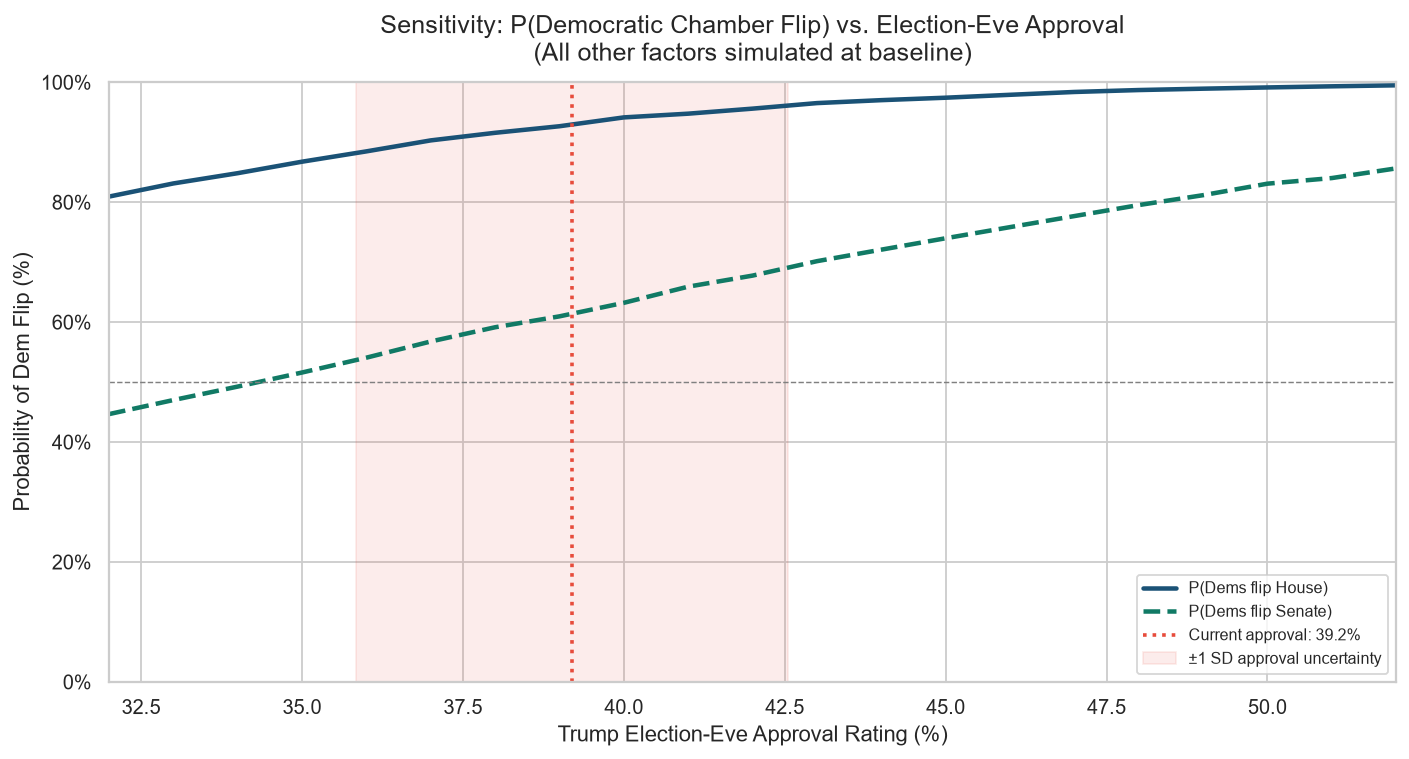

In [62]:
# --- CELL 18: Chart D — Scenario Funnel (Approval Sensitivity) ---
# "What if approval shifts?" — shows how P(flip) changes across approval levels

approval_range = np.arange(32, 53, 1)
p_house_flip_by_approval  = []
p_senate_flip_by_approval = []

for appr in approval_range:
    # Same sim, but fix approval at this level (no drift uncertainty)
    h = (HOUSE_SLOPE * appr + HOUSE_INTERCEPT
         + np.random.normal(HOUSE_MAP_ADJUSTMENT_MEAN, HOUSE_MAP_ADJUSTMENT_SD, 50_000)
         + np.random.normal(GENERIC_BALLOT_SEATS_MEAN, GENERIC_BALLOT_SEATS_SD, 50_000)
         + np.random.normal(0, HOUSE_RESID_SD, 50_000)
         + np.random.binomial(1, RECESSION_PROB, 50_000)
           * np.random.normal(RECESSION_IMPACT, RECESSION_SD, 50_000))
    s = (SENATE_SLOPE * appr + SENATE_INTERCEPT
         + np.random.normal(SENATE_MAP_ADJUSTMENT_MEAN, SENATE_MAP_ADJUSTMENT_SD, 50_000)
         + np.random.normal(0, SENATE_RESID_SD, 50_000))

    p_house_flip_by_approval.append((-np.round(h) >= HOUSE_DEM_THRESHOLD).mean())
    p_senate_flip_by_approval.append((-np.round(s) >= SENATE_DEM_THRESHOLD).mean())

fig, ax = plt.subplots(figsize=(11, 6))
ax.plot(approval_range, [p * 100 for p in p_house_flip_by_approval],
        color="#1a5276", linewidth=2.5, label="P(Dems flip House)")
ax.plot(approval_range, [p * 100 for p in p_senate_flip_by_approval],
        color="#117a65", linewidth=2.5, linestyle="--", label="P(Dems flip Senate)")

# Mark current approval
ax.axvline(APPROVAL_MEAN, color="#e74c3c", linewidth=2, linestyle=":",
           label=f"Current approval: {APPROVAL_MEAN}%")
ax.fill_betweenx([0, 100],
                 APPROVAL_MEAN - APPROVAL_TOTAL_SD,
                 APPROVAL_MEAN + APPROVAL_TOTAL_SD,
                 alpha=0.1, color="#e74c3c", label="±1 SD approval uncertainty")

ax.axhline(50, color="gray", linewidth=0.8, linestyle="--")
ax.set_title("Sensitivity: P(Democratic Chamber Flip) vs. Election-Eve Approval\n"
             "(All other factors simulated at baseline)",
             pad=12)
ax.set_xlabel("Trump Election-Eve Approval Rating (%)")
ax.set_ylabel("Probability of Dem Flip (%)")
ax.set_ylim(0, 100)
ax.set_xlim(32, 52)
ax.legend(fontsize=9)
ax.yaxis.set_major_formatter(mticker.PercentFormatter())
plt.tight_layout()
plt.savefig("chart_mc_sensitivity.png", bbox_inches="tight")
plt.show()

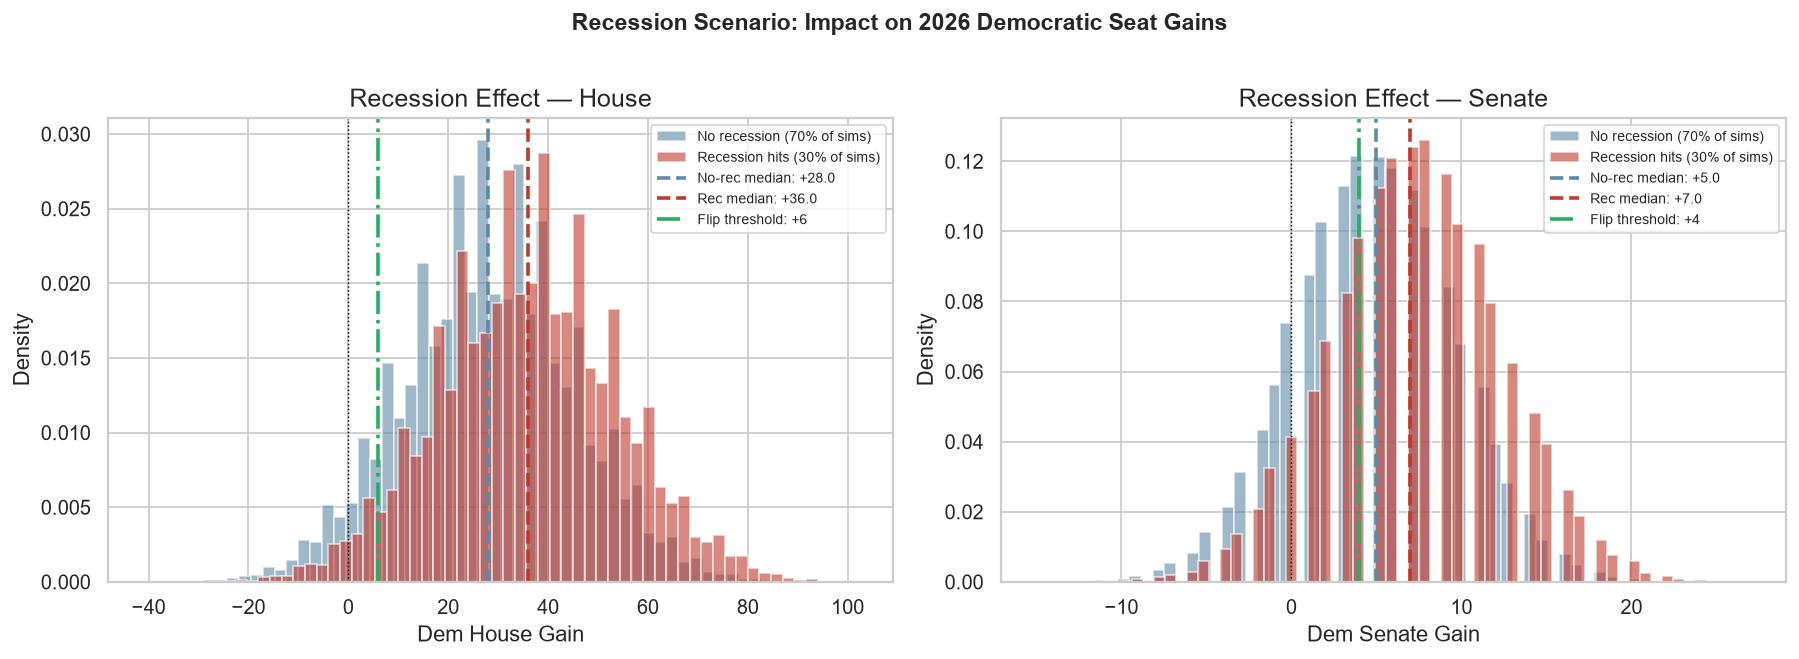

In [63]:
# --- CELL 19: Chart E — Recession Impact Comparison ---

fig, axes = plt.subplots(1, 2, figsize=(14, 5), sharey=False)

for i, (chamber, col, threshold, title) in enumerate([
    ("House",  "dem_house_gain",  HOUSE_DEM_THRESHOLD,  "House"),
    ("Senate", "dem_senate_gain", SENATE_DEM_THRESHOLD, "Senate"),
]):
    ax = axes[i]
    no_rec = results[results["recession_hit"] == 0][col]
    rec    = results[results["recession_hit"] == 1][col]

    ax.hist(no_rec, bins=60, density=True, alpha=0.6, color="#5d8aa8",
            label=f"No recession ({(~results['recession_hit'].astype(bool)).mean():.0%} of sims)")
    ax.hist(rec,    bins=60, density=True, alpha=0.6, color="#c0392b",
            label=f"Recession hits ({results['recession_hit'].mean():.0%} of sims)")

    ax.axvline(no_rec.median(), color="#5d8aa8", linewidth=2, linestyle="--",
               label=f"No-rec median: {no_rec.median():+.1f}")
    ax.axvline(rec.median(),    color="#c0392b", linewidth=2, linestyle="--",
               label=f"Rec median: {rec.median():+.1f}")
    ax.axvline(threshold, color="#27ae60", linewidth=2, linestyle="-.",
               label=f"Flip threshold: +{threshold}")
    ax.axvline(0, color="black", linewidth=0.8, linestyle=":")

    ax.set_title(f"Recession Effect — {title}")
    ax.set_xlabel(f"Dem {title} Gain")
    ax.set_ylabel("Density")
    ax.legend(fontsize=8)

plt.suptitle("Recession Scenario: Impact on 2026 Democratic Seat Gains",
             fontsize=13, fontweight="bold", y=1.01)
plt.tight_layout()
plt.savefig("chart_mc_recession_impact.png", bbox_inches="tight")
plt.show()

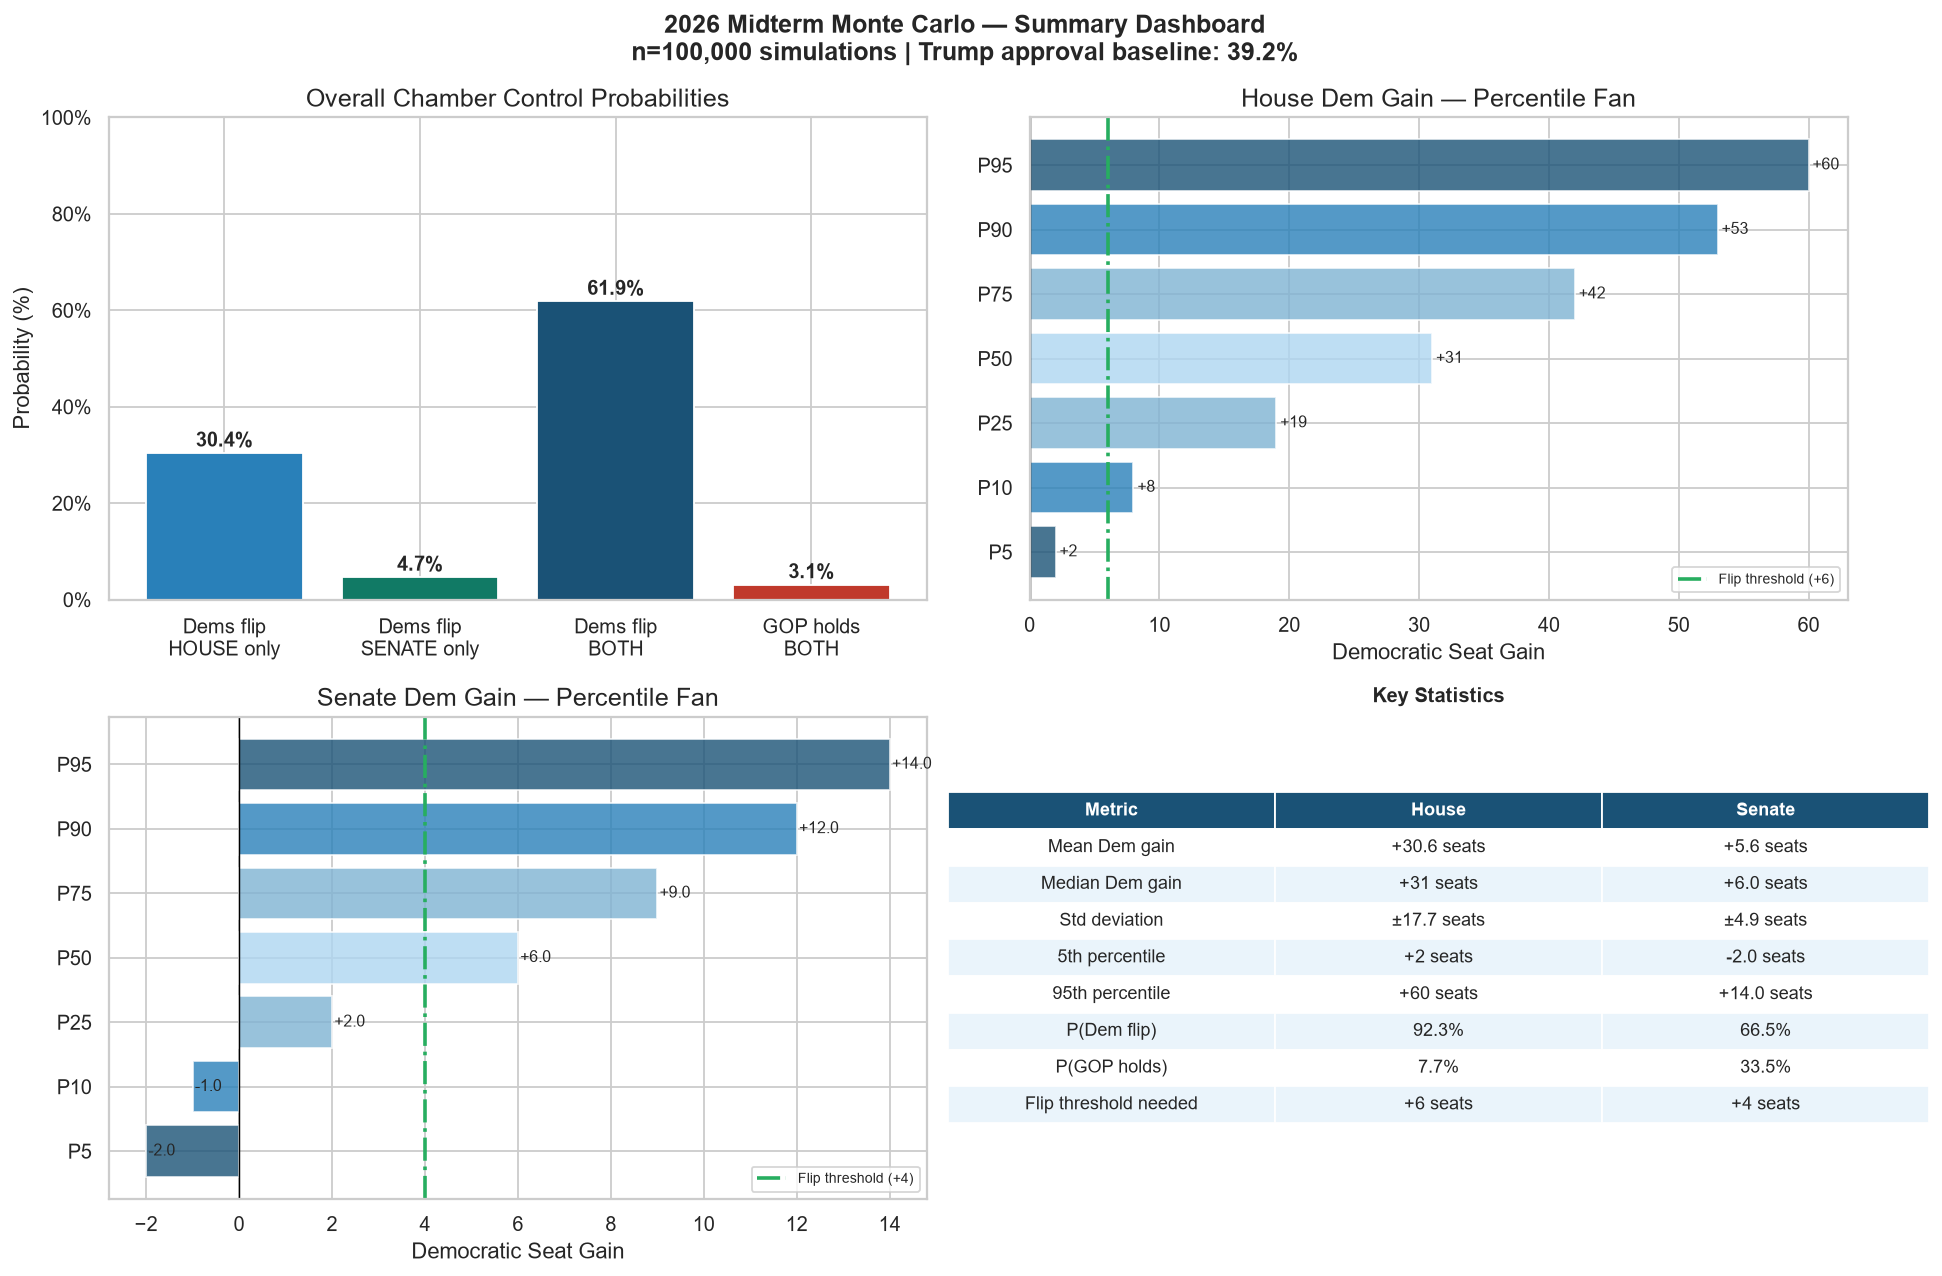


✅ Monte Carlo complete. All charts saved.

⚠️  DISCLAIMER: This is a statistical model for analytical purposes only.
   Projections carry wide uncertainty. Real outcomes depend on candidate
   quality, late-breaking events, turnout, and district-level dynamics
   that no aggregate model can fully capture.


In [64]:
# --- CELL 20: Final Monte Carlo Summary Dashboard ---

fig, axes = plt.subplots(2, 2, figsize=(15, 10))
fig.suptitle("2026 Midterm Monte Carlo — Summary Dashboard\n"
             f"n={N_SIMULATIONS:,} simulations | Trump approval baseline: {APPROVAL_MEAN}%",
             fontsize=14, fontweight="bold")

# ── Panel 1: Outcome probability bars ──────────────────────
ax1 = axes[0, 0]
scenarios = {
    "Dems flip\nHOUSE only":   q_house_dem,
    "Dems flip\nSENATE only":  q_senate_dem,
    "Dems flip\nBOTH":         q_both_dem,
    "GOP holds\nBOTH":         q_gop_both,
}
colors_sc = ["#2980b9", "#117a65", "#1a5276", "#c0392b"]
bars1 = ax1.bar(scenarios.keys(), [v * 100 for v in scenarios.values()],
                color=colors_sc, edgecolor="white")
for bar, val in zip(bars1, scenarios.values()):
    ax1.text(bar.get_x() + bar.get_width() / 2, bar.get_height() + 0.5,
             f"{val:.1%}", ha="center", va="bottom", fontsize=11, fontweight="bold")
ax1.set_ylabel("Probability (%)")
ax1.set_title("Overall Chamber Control Probabilities")
ax1.yaxis.set_major_formatter(mticker.PercentFormatter())
ax1.set_ylim(0, 100)

# ── Panel 2: House seat gain percentile fan ──────────────────
ax2 = axes[0, 1]
percentiles = [5, 10, 25, 50, 75, 90, 95]
h_pcts = np.percentile(results["dem_house_gain"], percentiles)
colors_fan = ["#1a5276", "#2980b9", "#7fb3d3", "#aed6f1", "#7fb3d3", "#2980b9", "#1a5276"]
for p, v, c in zip(percentiles, h_pcts, colors_fan):
    ax2.barh(f"P{p}", v, color=c, alpha=0.8, edgecolor="white")
    ax2.text(v + 0.3, f"P{p}", f"{v:+.0f}", va="center", fontsize=9)
ax2.axvline(HOUSE_DEM_THRESHOLD, color="#27ae60", linewidth=2,
            linestyle="-.", label=f"Flip threshold (+{HOUSE_DEM_THRESHOLD})")
ax2.axvline(0, color="black", linewidth=0.8)
ax2.set_title("House Dem Gain — Percentile Fan")
ax2.set_xlabel("Democratic Seat Gain")
ax2.legend(fontsize=8)

# ── Panel 3: Senate seat gain percentile fan ────────────────
ax3 = axes[1, 0]
s_pcts = np.percentile(results["dem_senate_gain"], percentiles)
for p, v, c in zip(percentiles, s_pcts, colors_fan):
    ax3.barh(f"P{p}", v, color=c, alpha=0.8, edgecolor="white")
    ax3.text(v + 0.05, f"P{p}", f"{v:+.1f}", va="center", fontsize=9)
ax3.axvline(SENATE_DEM_THRESHOLD, color="#27ae60", linewidth=2,
            linestyle="-.", label=f"Flip threshold (+{SENATE_DEM_THRESHOLD})")
ax3.axvline(0, color="black", linewidth=0.8)
ax3.set_title("Senate Dem Gain — Percentile Fan")
ax3.set_xlabel("Democratic Seat Gain")
ax3.legend(fontsize=8)

# ── Panel 4: Key statistics table ───────────────────────────
ax4 = axes[1, 1]
ax4.axis("off")
table_data = [
    ["Metric", "House", "Senate"],
    ["Mean Dem gain", f"{results['dem_house_gain'].mean():+.1f} seats",
                      f"{results['dem_senate_gain'].mean():+.1f} seats"],
    ["Median Dem gain", f"{results['dem_house_gain'].median():+.0f} seats",
                        f"{results['dem_senate_gain'].median():+.1f} seats"],
    ["Std deviation", f"±{results['dem_house_gain'].std():.1f} seats",
                      f"±{results['dem_senate_gain'].std():.1f} seats"],
    ["5th percentile", f"{np.percentile(results['dem_house_gain'], 5):+.0f} seats",
                       f"{np.percentile(results['dem_senate_gain'], 5):+.1f} seats"],
    ["95th percentile", f"{np.percentile(results['dem_house_gain'], 95):+.0f} seats",
                        f"{np.percentile(results['dem_senate_gain'], 95):+.1f} seats"],
    ["P(Dem flip)", f"{results['house_flip'].mean():.1%}",
                    f"{results['senate_flip'].mean():.1%}"],
    ["P(GOP holds)", f"{(~results['house_flip']).mean():.1%}",
                     f"{(~results['senate_flip']).mean():.1%}"],
    ["Flip threshold needed", f"+{HOUSE_DEM_THRESHOLD} seats", f"+{SENATE_DEM_THRESHOLD} seats"],
]

tbl = ax4.table(cellText=table_data[1:], colLabels=table_data[0],
                loc="center", cellLoc="center")
tbl.auto_set_font_size(False)
tbl.set_fontsize(10)
tbl.scale(1.2, 1.6)
for (row, col), cell in tbl.get_celld().items():
    if row == 0:
        cell.set_facecolor("#1a5276")
        cell.set_text_props(color="white", fontweight="bold")
    elif row % 2 == 0:
        cell.set_facecolor("#eaf4fb")
    cell.set_edgecolor("white")

ax4.set_title("Key Statistics", fontsize=11, fontweight="bold", pad=8)

plt.tight_layout()
plt.savefig("chart_mc_dashboard.png", bbox_inches="tight", dpi=150)
plt.show()
print("\n✅ Monte Carlo complete. All charts saved.")
print("\n⚠️  DISCLAIMER: This is a statistical model for analytical purposes only.")
print("   Projections carry wide uncertainty. Real outcomes depend on candidate")
print("   quality, late-breaking events, turnout, and district-level dynamics")
print("   that no aggregate model can fully capture.")

In [65]:
# ============================================================
# CELL 21: Bayesian Updating Setup
# Prior = historical midterm patterns
# Likelihood = incoming polls update our belief about approval
# Posterior = revised seat-change distribution
# ============================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import seaborn as sns
from scipy import stats
from scipy.stats import norm, gaussian_kde
import ipywidgets as widgets
from IPython.display import display, clear_output
import warnings
warnings.filterwarnings("ignore")

np.random.seed(42)
print("✅ Libraries loaded.")

✅ Libraries loaded.


In [66]:
# --- CELL 22: Define the Bayesian Framework ---
#
# We model approval as a Gaussian with a conjugate Normal-Normal update.
#
#   Prior:      μ₀ ~ N(prior_mean, prior_sd²)       ← what history tells us
#   Likelihood: x_obs ~ N(μ, σ_poll²)               ← each new poll
#   Posterior:  μ | x ~ N(μ_post, σ_post²)           ← updated belief
#
# Posterior parameters (conjugate update):
#
#   σ_post² = 1 / (1/σ_prior² + n/σ_poll²)
#   μ_post  = σ_post² × (μ_prior/σ_prior² + Σx_i/σ_poll²)
#
# This means every new poll tightens our uncertainty and pulls
# the mean toward the data — exactly the right behaviour.

# ── Historical Prior ─────────────────────────────────────────
# Based on approval ratings of presidents who lost the House
# (all modern midterms): mean ~44%, SD ~8pp — deliberately wide
PRIOR_MEAN = 44.0   # historical average pre-midterm approval
PRIOR_SD   =  8.0   # reflects genuine historical spread

# ── Poll observation noise ────────────────────────────────────
POLL_SD = 3.0       # typical national poll MOE / √2

# ── Seed poll history with real-ish RCP datapoints ───────────
# (month, observed_approval)
poll_history = [
    ("2025-Q2",  46.0),
    ("2025-Q3",  44.0),
    ("2025-Q4",  42.0),
    ("2026-Q1",  40.5),
    ("2026-Q2",  39.5),
    ("2026-Q3",  39.2),   # most recent — Sep 2026
]

def bayesian_update(prior_mean, prior_sd, observations, poll_sd=POLL_SD):
    """
    Conjugate Normal-Normal sequential Bayesian update.
    Returns list of (posterior_mean, posterior_sd) after each observation.
    """
    history = []
    mu    = prior_mean
    sigma = prior_sd

    for label, x in observations:
        # Posterior variance
        sigma_post = np.sqrt(1.0 / (1.0/sigma**2 + 1.0/poll_sd**2))
        # Posterior mean
        mu_post = sigma_post**2 * (mu / sigma**2 + x / poll_sd**2)
        history.append({
            "period":        label,
            "observation":   x,
            "prior_mean":    mu,
            "prior_sd":      sigma,
            "posterior_mean": mu_post,
            "posterior_sd":   sigma_post,
        })
        mu, sigma = mu_post, sigma_post   # roll forward

    return pd.DataFrame(history)

update_history = bayesian_update(PRIOR_MEAN, PRIOR_SD, poll_history)
print(update_history[["period","observation","posterior_mean","posterior_sd"]].to_string(index=False))

 period  observation  posterior_mean  posterior_sd
2025-Q2         46.0       45.753425      2.808988
2025-Q3         44.0       44.934307      2.050458
2025-Q4         42.0       44.000000      1.692829
2026-Q1         40.5       43.154717      1.474308
2026-Q2         39.5       42.443769      1.323163
2026-Q3         39.2       41.915522      1.210640


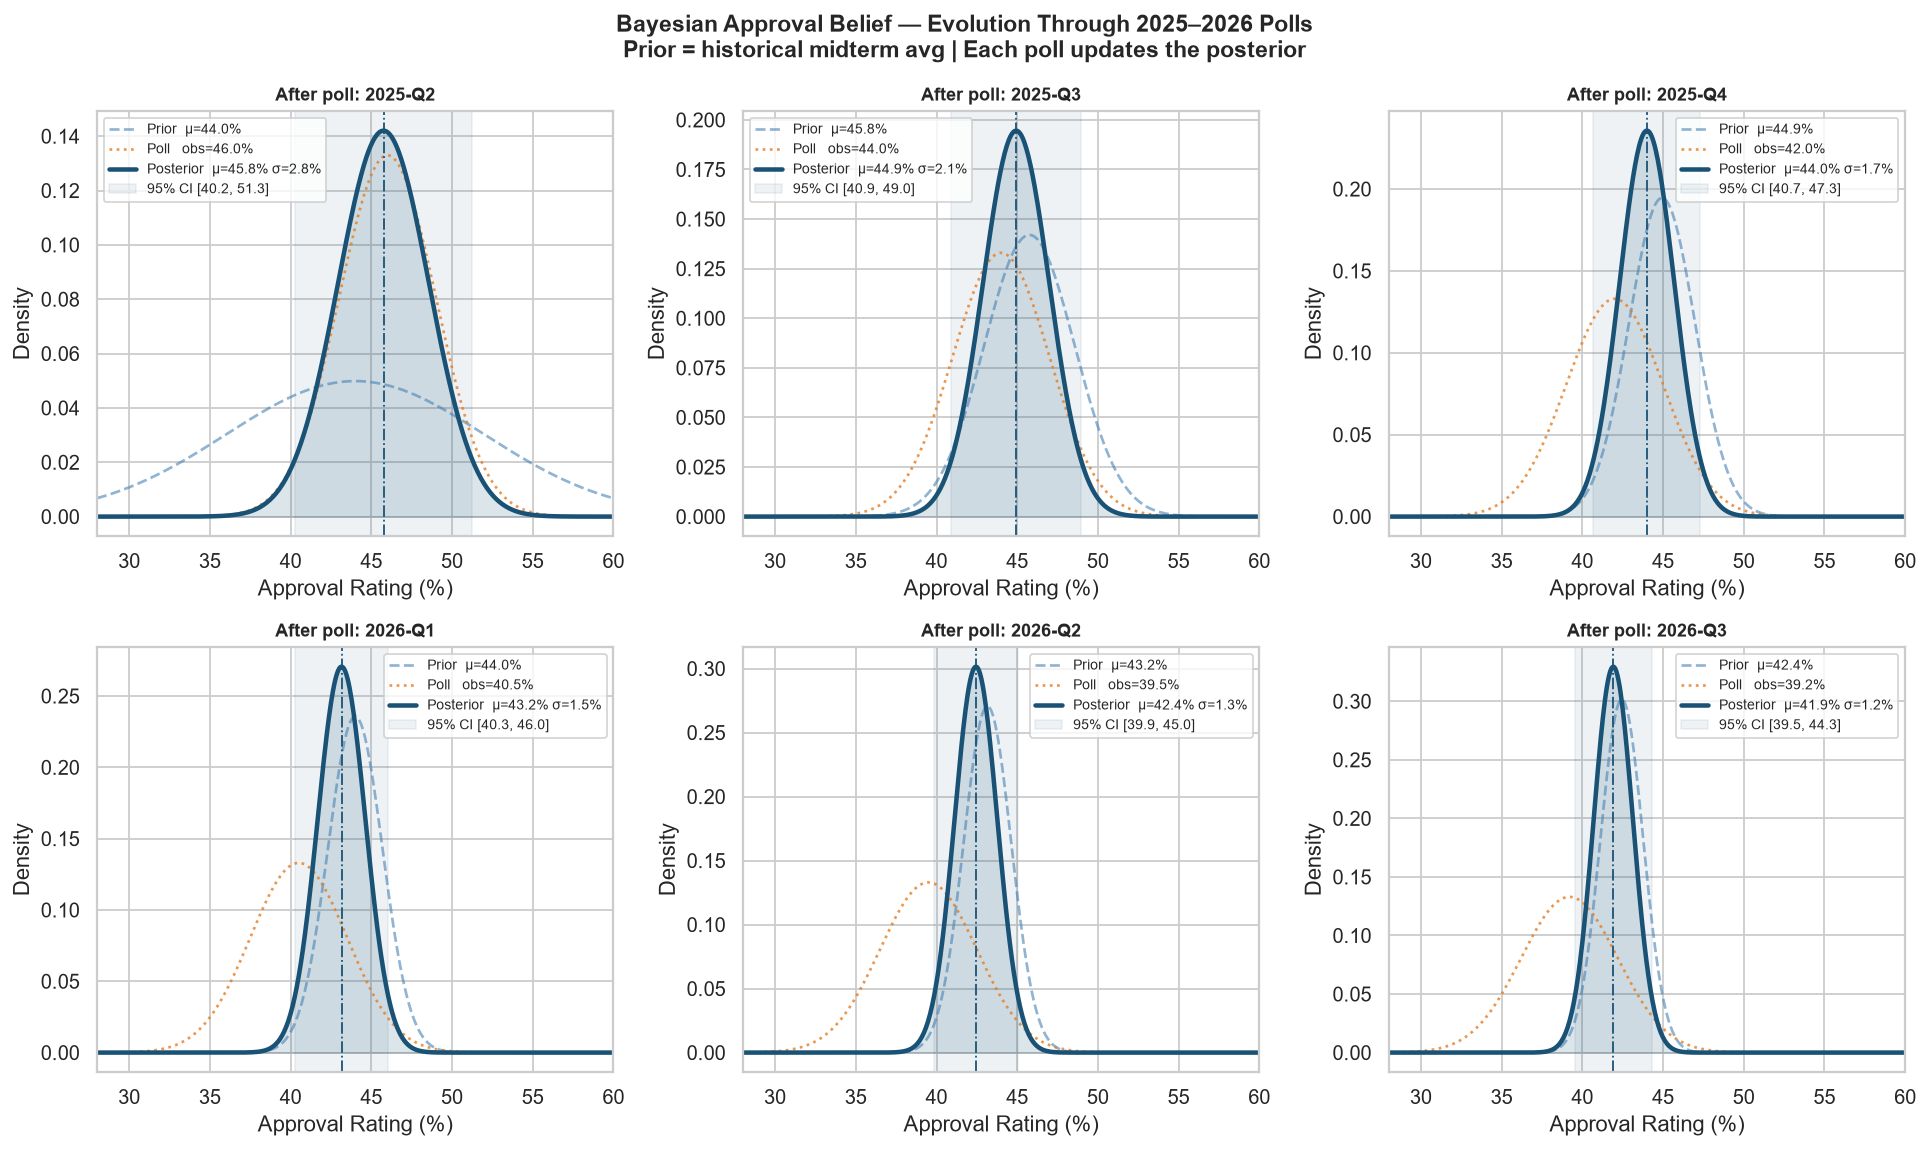

In [67]:
# --- CELL 23: Chart — Bayesian Belief Evolution ---
# Shows how the approval distribution tightens with each new poll

fig, axes = plt.subplots(2, 3, figsize=(15, 9))
axes = axes.flatten()
x_range = np.linspace(28, 60, 500)

# Prior
prior_pdf = norm.pdf(x_range, PRIOR_MEAN, PRIOR_SD)

for i, row in update_history.iterrows():
    ax = axes[i]

    # Prior at this stage
    ax.plot(x_range, norm.pdf(x_range, row["prior_mean"], row["prior_sd"]),
            color="steelblue", linewidth=1.5, linestyle="--",
            alpha=0.6, label=f"Prior  μ={row['prior_mean']:.1f}%")

    # Likelihood (single poll)
    ax.plot(x_range, norm.pdf(x_range, row["observation"], POLL_SD),
            color="#e67e22", linewidth=1.5, linestyle=":",
            alpha=0.8, label=f"Poll   obs={row['observation']:.1f}%")

    # Posterior
    post_pdf = norm.pdf(x_range, row["posterior_mean"], row["posterior_sd"])
    ax.plot(x_range, post_pdf, color="#1a5276", linewidth=2.5,
            label=f"Posterior  μ={row['posterior_mean']:.1f}% σ={row['posterior_sd']:.1f}%")
    ax.fill_between(x_range, post_pdf, alpha=0.15, color="#1a5276")

    # 95% credible interval
    ci_lo = norm.ppf(0.025, row["posterior_mean"], row["posterior_sd"])
    ci_hi = norm.ppf(0.975, row["posterior_mean"], row["posterior_sd"])
    ax.axvspan(ci_lo, ci_hi, alpha=0.07, color="#1a5276",
               label=f"95% CI [{ci_lo:.1f}, {ci_hi:.1f}]")

    ax.axvline(row["posterior_mean"], color="#1a5276", linewidth=1, linestyle="-.")
    ax.set_title(f"After poll: {row['period']}", fontsize=10, fontweight="bold")
    ax.set_xlabel("Approval Rating (%)")
    ax.set_ylabel("Density")
    ax.legend(fontsize=7.5)
    ax.set_xlim(28, 60)

plt.suptitle("Bayesian Approval Belief — Evolution Through 2025–2026 Polls\n"
             "Prior = historical midterm avg | Each poll updates the posterior",
             fontsize=13, fontweight="bold")
plt.tight_layout()
plt.savefig("chart_bayesian_evolution.png", bbox_inches="tight")
plt.show()

In [68]:
# --- CELL 24: Bayesian → Monte Carlo Bridge ---
# The posterior approval feeds into the MC seat-change model.
# This function is the core engine called by the widgets below.

# Regression coefficients (from Cell 14)
HOUSE_SLOPE     = -1.42;  HOUSE_INTERCEPT  = 18.5;  HOUSE_RESID_SD  = 14.8
SENATE_SLOPE    = -0.28;  SENATE_INTERCEPT =  5.1;  SENATE_RESID_SD =  4.2
HOUSE_DEM_THRESHOLD  = 6
SENATE_DEM_THRESHOLD = 4

def run_bayesian_mc(
    posterior_mean,       # Bayesian posterior approval mean
    posterior_sd,         # Bayesian posterior approval SD
    n_sims         = 50_000,
    recession_prob = 0.30,
    recession_impact_mean = -8,
    recession_impact_sd   =  5,
    house_map_adj_mean    = -3,
    house_map_adj_sd      =  4,
    generic_mean          = 12,
    generic_sd            =  6,
):
    """Run Monte Carlo using Bayesian posterior as the approval prior."""
    # Sample approval from posterior
    sim_approval = np.random.normal(posterior_mean, posterior_sd, n_sims)
    sim_approval = np.clip(sim_approval, 25, 65)

    # Regression-predicted seat changes
    house_reg  = HOUSE_SLOPE  * sim_approval + HOUSE_INTERCEPT
    senate_reg = SENATE_SLOPE * sim_approval + SENATE_INTERCEPT

    # Structural adjustments
    house_map  = np.random.normal(house_map_adj_mean, house_map_adj_sd,  n_sims)
    senate_map = np.random.normal(0, 2.0, n_sims)
    generic    = np.random.normal(generic_mean, generic_sd, n_sims)

    # Residuals
    h_resid = np.random.normal(0, HOUSE_RESID_SD,  n_sims)
    s_resid = np.random.normal(0, SENATE_RESID_SD, n_sims)

    # Economic shock
    recession  = np.random.binomial(1, recession_prob, n_sims)
    rec_effect = recession * np.random.normal(recession_impact_mean,
                                               recession_impact_sd, n_sims)

    # Final seat changes (from R perspective; negative = R lose seats)
    house_total  = house_reg  + house_map + generic + h_resid + rec_effect
    senate_total = senate_reg + senate_map + s_resid + 0.3 * rec_effect

    dem_house  = -np.round(house_total).astype(int)
    dem_senate = -np.round(senate_total).astype(int)

    return {
        "dem_house":       dem_house,
        "dem_senate":      dem_senate,
        "sim_approval":    sim_approval,
        "p_house_flip":    (dem_house  >= HOUSE_DEM_THRESHOLD).mean(),
        "p_senate_flip":   (dem_senate >= SENATE_DEM_THRESHOLD).mean(),
        "p_both_flip":     ((dem_house >= HOUSE_DEM_THRESHOLD) &
                            (dem_senate >= SENATE_DEM_THRESHOLD)).mean(),
        "p_gop_holds":     ((dem_house  < HOUSE_DEM_THRESHOLD) &
                            (dem_senate < SENATE_DEM_THRESHOLD)).mean(),
        "house_median":    np.median(dem_house),
        "senate_median":   np.median(dem_senate),
        "house_p5":        np.percentile(dem_house,  5),
        "house_p95":       np.percentile(dem_house, 95),
        "senate_p5":       np.percentile(dem_senate,  5),
        "senate_p95":      np.percentile(dem_senate, 95),
    }

# Quick sanity-check run using current posterior
current_posterior = update_history.iloc[-1]
baseline = run_bayesian_mc(current_posterior["posterior_mean"],
                            current_posterior["posterior_sd"])
print(f"Baseline | P(House flip): {baseline['p_house_flip']:.1%} | "
      f"P(Senate flip): {baseline['p_senate_flip']:.1%} | "
      f"P(GOP holds both): {baseline['p_gop_holds']:.1%}")

Baseline | P(House flip): 95.5% | P(Senate flip): 78.5% | P(GOP holds both): 1.1%
